<div align="center">

# Modelo de Clasificación del Riesgo de Entrega Tardía en DataCo

### Big Data

**Jonathan Barrantes · Joy D. Chávez Pomacaja · María de Jesús Peña García · Abby Chavarría Bolaños**

Universidad Fidélitas  
San José, Costa Rica

</div>

---

### Autores y contacto

| Integrante                 | Correo institucional        |
| -------------------------- | --------------------------- |
| Jonathan Barrantes         | jbarrantes40180@ufide.ac.cr |
| Joy D. Chávez Pomacaja     | jchavez60736@ufide.ac.cr    |
| María de Jesús Peña García | mpena30226@ufide.ac.cr      |
| Abby Chavarría Bolaños     | achavarria70596@ufide.ac.cr |

---

## Resumen

> Este proyecto busca predecir el riesgo de entregas tardías en DataCo mediante un modelo de clasificación basado en aprendizaje automático. Se utilizará el conjunto de datos **DataCo Smart Supply Chain** y la variable objetivo `Late_delivery_risk`.
>
> Se explorarán y prepararán los datos, se analizarán las características asociadas con los retrasos y se comparará el desempeño de distintos modelos. Las predicciones utilizarán información disponible al registrar el pedido, excluyendo datos posteriores que revelen el resultado de la entrega.
>
> Se pretende generar estimaciones que permitan identificar pedidos con mayor riesgo y apoyar la planificación logística.

**Palabras clave:** aprendizaje automático · cadena de suministro · clasificación · entregas tardías · planificación logística

---

## I. ANTECEDENTES

El conjunto de datos DataCo Smart Supply Chain reúne información histórica relacionada con operaciones comerciales y logísticas, incluyendo características de clientes, productos, pedidos, modalidades de envío y estados de entrega [1].

La información disponible permite examinar diferencias entre los tiempos de envío programados y reales, así como identificar registros asociados con entregas tardías.

El cumplimiento de los plazos de entrega constituye un aspecto relevante de la gestión logística, debido a su relación con la planificación de operaciones, la utilización de recursos y la satisfacción de los clientes.

En este contexto, el análisis de datos y el aprendizaje automático ofrecen herramientas para estudiar patrones históricos y desarrollar modelos capaces de estimar el riesgo de retraso a partir de características conocidas previamente.

---

## II. DEFINICIÓN DEL PROBLEMA

El conjunto de datos analizado contiene registros de operaciones logísticas con diferentes modalidades de envío, destinos y características comerciales.

La variable `Late_delivery_risk` permite identificar los registros etiquetados con riesgo de entrega tardía. En el conjunto analizado, aproximadamente el 54.83 % de los registros presenta el valor 1.

El problema consiste en determinar si las características disponibles al registrar un pedido permiten anticipar adecuadamente el riesgo de retraso, sin utilizar información generada después de la operación que revele directamente el resultado de la entrega.

Por lo tanto, se plantea desarrollar un modelo de clasificación que identifique patrones asociados con las entregas tardías y permita estimar su riesgo antes de conocer el resultado del envío.

---

## III. JUSTIFICACIÓN

El proyecto permitiría generar estimaciones del riesgo de entrega tardía para apoyar la planificación logística de DataCo. Esta información facilitaría la identificación de pedidos que requieren mayor atención y la priorización de su seguimiento antes del vencimiento de los plazos.

Asimismo, el análisis de las características de los pedidos, sus destinos y modalidades de envío aportaría criterios para orientar decisiones preventivas.

Estos beneficios podrían contribuir a mejorar la puntualidad de las entregas, controlar los costos asociados con los retrasos y favorecer la satisfacción de los clientes.

---

## IV. OBJETIVO GENERAL

> Desarrollar un modelo de clasificación mediante técnicas de Big Data y aprendizaje automático para predecir el riesgo de entregas tardías en DataCo y apoyar la planificación logística.

---

## V. OBJETIVOS ESPECÍFICOS

1. Analizar las características geográficas, logísticas y de los pedidos presentes en el conjunto de datos, identificando sus relaciones con el riesgo de entrega tardía.

2. Evaluar la calidad de los datos mediante la identificación de valores faltantes, inconsistencias, valores atípicos y distribuciones que puedan afectar el desempeño de los modelos.

3. Preparar los datos mediante técnicas de limpieza, transformación, codificación, escalamiento e imputación, según las necesidades identificadas.

4. Seleccionar y construir variables predictoras relevantes para estimar el riesgo de entrega tardía, considerando únicamente la información disponible al registrar el pedido.

5. Construir distintos modelos de clasificación mediante algoritmos de aprendizaje supervisado para estimar el riesgo de entrega tardía de los pedidos.

6. Comparar el desempeño de los modelos mediante procedimientos de validación y métricas de clasificación, como exactitud, precisión, exhaustividad y F1-score, para determinar su capacidad de identificar pedidos con riesgo de retraso.

7. Ajustar y seleccionar el modelo que presente un equilibrio adecuado entre capacidad predictiva y complejidad, y evaluar su desempeño final sobre un conjunto de prueba reservado para estimar su capacidad de generalización.

---

## VI. DESCRIPCIÓN DEL CONJUNTO DE DATOS

El proyecto utilizará el archivo `DataCoSupplyChainDataset.csv` del conjunto **DataCo Smart Supply Chain**, disponible públicamente en Kaggle [1].

Este contiene información histórica sobre clientes, productos, pedidos y operaciones de envío de DataCo Global.

| Característica                        | Descripción                                                                                                                                                                                                                          |
| ------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------ |
| **Estructura**                        | El archivo utilizado contiene **180 519 registros y 44 variables**. El diccionario de datos disponible en el repositorio contempla 53 campos, entre ellos nueve identificadores que no están presentes en el CSV analizado.          |
| **Unidad de análisis**                | Cada fila representa un registro del conjunto de datos. El archivo utilizado no incluye `Order Id`, por lo que el número de filas no debe interpretarse automáticamente como el número de pedidos únicos.                            |
| **Variable objetivo**                 | `Late_delivery_risk` es una variable binaria que identifica registros etiquetados como entrega tardía mediante `1` y registros no etiquetados como tardíos mediante `0`.                                                             |
| **Variables categóricas**             | Incluye modalidad de envío, categoría del producto, mercado, región de destino, tipo de transacción y segmento del cliente.                                                                                                          |
| **Variables numéricas**               | Incluye días programados de envío, cantidad de artículos, precios, descuentos, importes de venta y ganancias.                                                                                                                        |
| **Variables temporales**              | Contiene fechas de pedido y envío. La fecha de registro del pedido permitirá obtener características como mes y día de la semana.                                                                                                    |
| **Información posterior a la compra** | Incluye días reales de envío y estados de entrega. Estos campos podrán utilizarse para el análisis histórico, pero se excluirán de las entradas del modelo predictivo cuando revelen información posterior al momento de predicción. |

### Variable objetivo

| Valor | Clasificación       |
| :---: | ------------------- |
|  `0`  | Entrega sin retraso |
|  `1`  | Entrega tardía      |

---

## VII. REFERENCIAS

**[1]** S. Tiwari, _DataCo SMART SUPPLY CHAIN FOR BIG DATA ANALYSIS_, Kaggle, conjunto de datos. [En línea]. Disponible en:  
https://www.kaggle.com/datasets/shashwatwork/dataco-smart-supply-chain-for-big-data-analysis  
[Consultado: 22 de septiembre de 2026].


# Análisis exploratorio y preparación inicial de los datos

## 1. Carga y exploración inicial del conjunto de datos


In [3]:
### 1.1 Importación de librerías
import pandas as pd
import numpy as np

In [4]:
### 1.2 Carga del conjunto de datos
from pathlib import Path

rutas_dataset = [
    Path("Dataset/DataCoSupplyChainDataset.csv"),
    Path("DataCoSupplyChainDataset.csv")
]

ruta_dataset = next((ruta for ruta in rutas_dataset if ruta.exists()), None)

if ruta_dataset is None:
    raise FileNotFoundError(
        "No se encontró DataCoSupplyChainDataset.csv. "
        "Colóquelo en la carpeta Dataset/ o junto al notebook."
    )

df = pd.read_csv(
    ruta_dataset,
    encoding="latin1",
    sep=";",
    low_memory=False
)

df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Name,Customer City,Customer Country,...,Order State,Order Status,Order Zipcode,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,Sporting Goods,Caguas,Puerto Rico,...,Java Occidental,COMPLETE,NaN,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,Sporting Goods,Caguas,Puerto Rico,...,Rajastï¿,PENDING,NaN,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,Sporting Goods,San Jose,EE. UU.,...,Rajastï¿,CLOSED,NaN,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,Sporting Goods,Los Angeles,EE. UU.,...,Queensland,COMPLETE,NaN,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,Sporting Goods,Caguas,Puerto Rico,...,Queensland,PENDING_PAYMENT,NaN,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [5]:

### 1.3 Verificación de la estructura del CSV

print(f"Registros: {df.shape[0]:,}")
print(f"Variables: {df.shape[1]}")

Registros: 180,519
Variables: 44


In [6]:
### 1.4 Estructura y tipos de datos
resumen_estructura = pd.DataFrame({
    "Variable": df.columns,
    "Tipo de dato": df.dtypes.astype(str).values
})

print(f"Total de variables: {df.shape[1]}")
display(resumen_estructura)

Total de variables: 44


,Variable,Tipo de dato
0,Type,str
1,Days for shipping (real),int64
2,Days for shipment (scheduled),int64
3,Benefit per order,float64
4,Sales per customer,float64
5,Delivery Status,str
6,Late_delivery_risk,int64
7,Category Name,str
8,Customer City,str
9,Customer Country,str


In [7]:
### 1.5 Valores faltantes
resumen_nulos = pd.DataFrame({
    "Valores faltantes": df.isnull().sum(),
    "Porcentaje (%)": (df.isnull().sum() / len(df) * 100).round(2)
})

resumen_nulos = resumen_nulos[resumen_nulos["Valores faltantes"] > 0]
resumen_nulos = resumen_nulos.sort_values(
    by="Valores faltantes",
    ascending=False
)

display(resumen_nulos)

,Valores faltantes,Porcentaje (%)
Product Description,180519,100.00
Order Zipcode,155679,86.24
Customer Lname,8,0.00
Customer Zipcode,3,0.00


Se identificaron valores faltantes en cuatro variables. `Product Description` presenta un **100 % de valores faltantes**, mientras que `Order Zipcode` presenta un **86.24 %**. Por su parte, `Customer Lname` y `Customer Zipcode` presentan únicamente 8 y 3 valores faltantes, respectivamente, por lo que su proporción respecto al total de registros es mínima.

En esta etapa únicamente se documentan los valores faltantes identificados. Su tratamiento se determinará posteriormente durante la preparación de los datos.


In [8]:
### 1.6 Estadísticas descriptivas
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Days for shipping (real),180519.0,3.497654,1.623722,0.000000,2.000000,3.000000,5.000000,6.000000
Days for shipment (scheduled),180519.0,2.931847,1.374449,0.000000,2.000000,4.000000,4.000000,4.000000
Benefit per order,180519.0,21.974989,104.433526,-4274.979980,7.000000,31.520000,64.800003,911.799988
Sales per customer,180519.0,183.107609,120.043670,7.490000,104.379997,163.990005,247.399994,1939.989990
Late_delivery_risk,180519.0,0.548291,0.497664,0.000000,0.000000,1.000000,1.000000,1.000000
Customer Zipcode,180516.0,35921.126914,37542.461122,603.000000,725.000000,19380.000000,78207.000000,99205.000000
Latitude,180519.0,29.719955,9.813646,-33.937553,18.265432,33.144863,39.279617,48.781933
Longitude,180519.0,-84.915675,21.433241,-158.025986,-98.446312,-76.847908,-66.370583,115.263077
Order Item Discount,180519.0,20.664741,21.800901,0.000000,5.400000,14.000000,29.990000,500.000000
Order Item Discount Rate,180519.0,0.101668,0.070415,0.000000,0.040000,0.100000,0.160000,0.250000


Las estadísticas descriptivas muestran diferencias importantes en los rangos y escalas de las variables numéricas. Las variables monetarias presentan una mayor amplitud de valores, mientras que otras variables, como tasas, cantidades y días de envío, se encuentran en rangos considerablemente menores.

También se identifican variables numéricas que no deben interpretarse como continuas, como `Late_delivery_risk`, los códigos postales y `Product Status`. Además, `Product Description` no contiene observaciones válidas y `Product Status` presenta un único valor en todos los registros.

Algunas variables presentan estadísticas descriptivas idénticas, como `Benefit per order` y `Order Profit Per Order`, así como `Sales per customer` y `Order Item Total`. Estas posibles redundancias deberán revisarse posteriormente durante la preparación de los datos.


In [9]:
### 1.7 Identificación de variables continuas
variables_continuas = [
    "Benefit per order",
    "Sales per customer",
    "Latitude",
    "Longitude",
    "Order Item Discount",
    "Order Item Discount Rate",
    "Order Item Product Price",
    "Order Item Profit Ratio",
    "Sales",
    "Order Item Total",
    "Order Profit Per Order",
    "Product Price"
]

print(f"Variables continuas identificadas: {len(variables_continuas)}")
variables_continuas

Variables continuas identificadas: 12


['Benefit per order',
 'Sales per customer',
 'Latitude',
 'Longitude',
 'Order Item Discount',
 'Order Item Discount Rate',
 'Order Item Product Price',
 'Order Item Profit Ratio',
 'Sales',
 'Order Item Total',
 'Order Profit Per Order',
 'Product Price']

## 2. Análisis de distribuciones

Se analizaron las distribuciones de las variables numéricas mediante histogramas, estadísticas descriptivas y diagramas de cajas y bigotes. Se examinaron características como la asimetría, la concentración de valores, la dispersión y la presencia de valores atípicos. Asimismo, se evaluaron transformaciones para reducir la asimetría de determinadas variables.


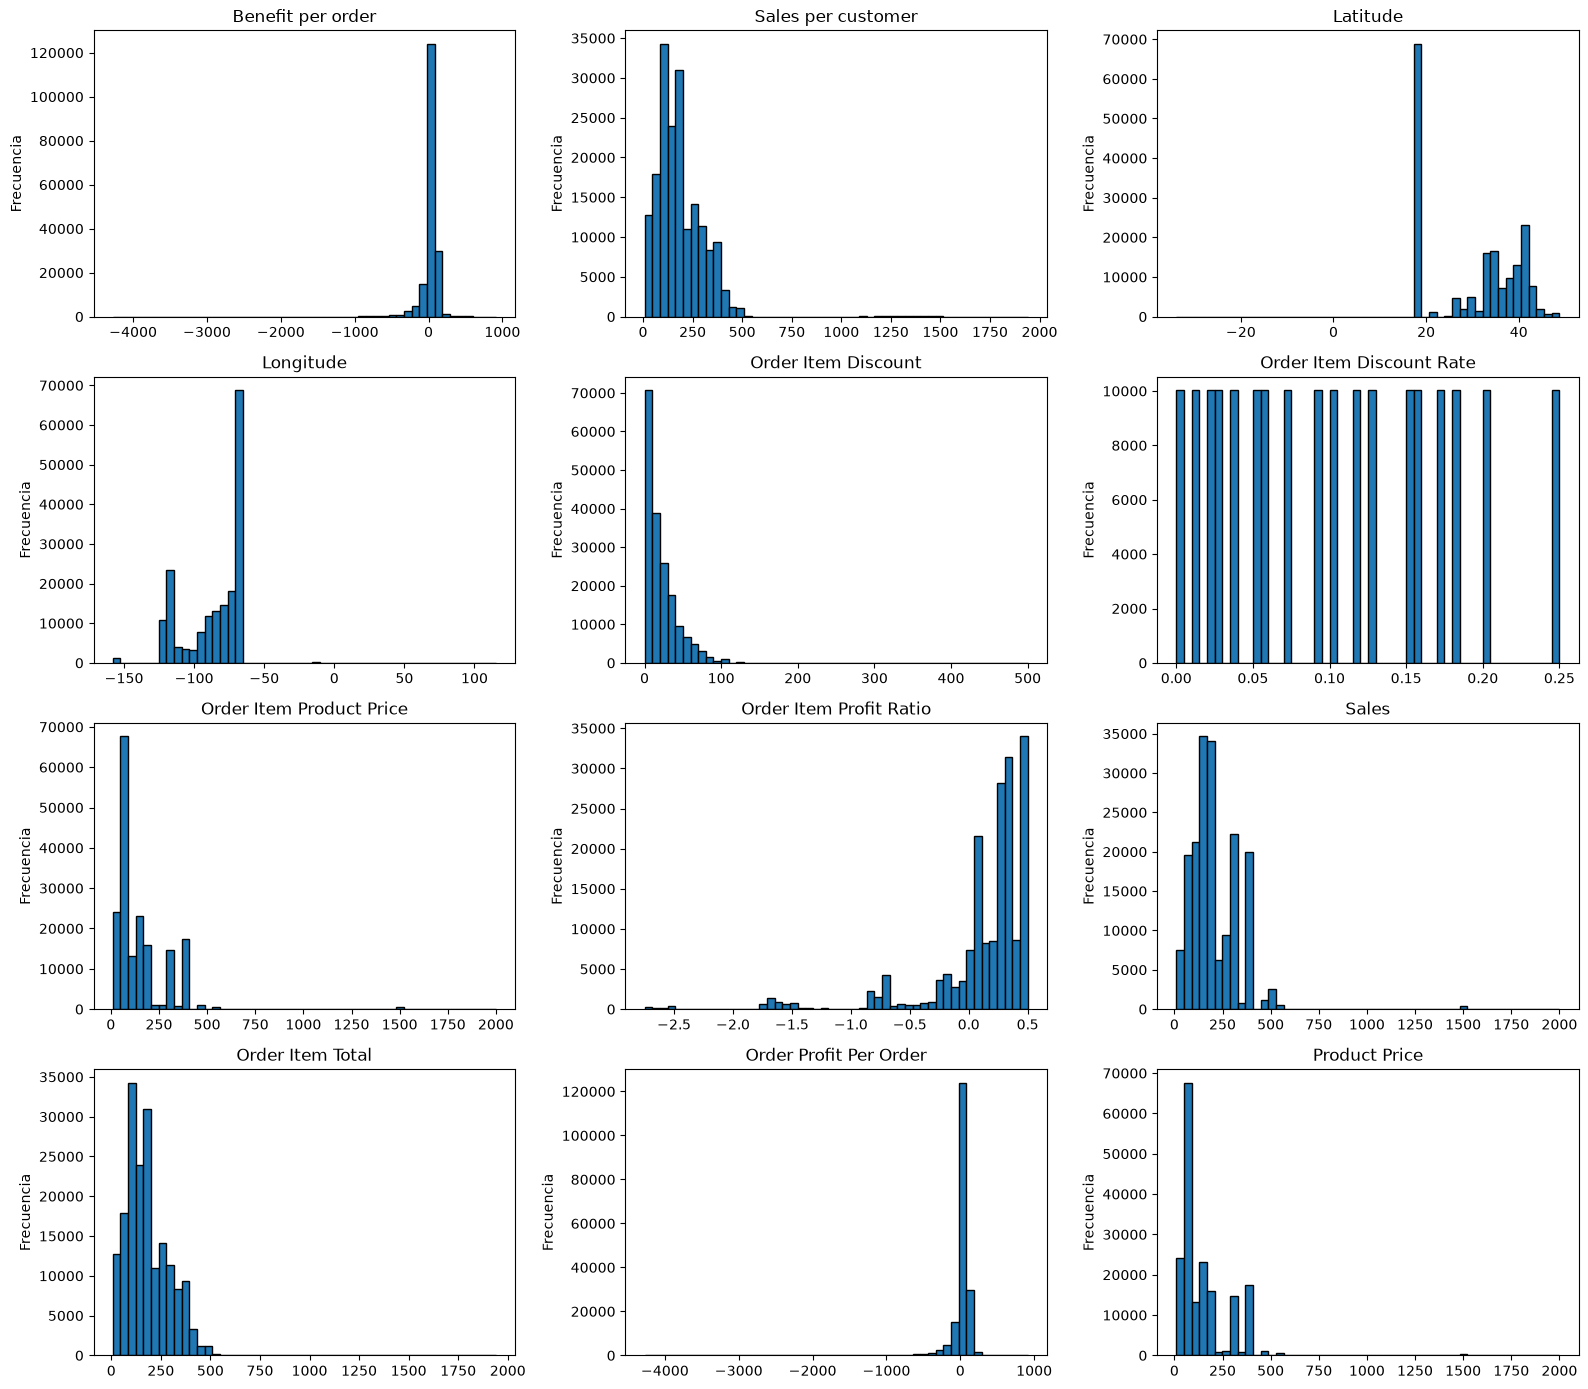

In [10]:
### 2.1 Histogramas de las variables continuas
import matplotlib.pyplot as plt
plt.figure(figsize=(16, 14))

for i, col in enumerate(variables_continuas, start=1):
    plt.subplot(4, 3, i)
    plt.hist(df[col], bins=50, edgecolor="black")
    plt.title(col)
    plt.ylabel("Frecuencia")

plt.tight_layout()
plt.show()

In [11]:
### 2.2 Resumen de forma de las distribuciones
resumen_distribuciones = pd.DataFrame({
    "Mínimo": df[variables_continuas].min(),
    "Máximo": df[variables_continuas].max(),
    "Media": df[variables_continuas].mean(),
    "Mediana": df[variables_continuas].median(),
    "Asimetría": df[variables_continuas].skew(),
    "Valores únicos": df[variables_continuas].nunique()
})
display(resumen_distribuciones.round(2))

,Mínimo,Máximo,Media,Mediana,Asimetría,Valores únicos
Benefit per order,-4274.98,911.80,21.97,31.52,-4.74,21998
Sales per customer,7.49,1939.99,183.11,163.99,2.89,2927
Latitude,-33.94,48.78,29.72,33.14,-0.10,11250
Longitude,-158.03,115.26,-84.92,-76.85,-0.50,4487
Order Item Discount,0.00,500.00,20.66,14.00,3.04,1017
Order Item Discount Rate,0.00,0.25,0.10,0.10,0.34,18
Order Item Product Price,9.99,1999.99,141.23,59.99,3.19,75
Order Item Profit Ratio,-2.75,0.50,0.12,0.27,-2.89,162
Sales,9.99,1999.99,203.77,199.92,2.88,193
Order Item Total,7.49,1939.99,183.11,163.99,2.89,2927


### 2.3 Interpretación de las distribuciones

| Variable                                    | Distribución                                 |
| ------------------------------------------- | -------------------------------------------- |
| Sales, Sales per customer, Order Item Total | Sesgada a la derecha                         |
| Order Item Discount                         | Sesgada a la derecha y acotada               |
| Product Price, Order Item Product Price     | Sesgada a la derecha y multimodal            |
| Benefit per order, Order Profit Per Order   | Sesgada a la izquierda                       |
| Order Item Profit Ratio                     | Sesgada a la izquierda y acotada             |
| Order Item Discount Rate                    | Discreta, aproximadamente uniforme y acotada |
| Latitude, Longitude                         | Multimodal                                   |

**Variables sesgadas a la derecha:** Las variables relacionadas con ventas, precios y descuentos presentan concentraciones importantes en valores relativamente bajos, acompañadas de observaciones mucho mayores. Por ejemplo, `Sales` presenta una asimetría positiva de aproximadamente 2.88, con valores que alcanzan casi 2 000.

**Variables sesgadas a la izquierda:** `Benefit per order` y `Order Profit Per Order` presentan asimetría negativa debido a la presencia de pérdidas de gran magnitud. En `Benefit per order`, el valor mínimo alcanza aproximadamente -4 274.98, mientras que la media (21.97) se encuentra por debajo de la mediana (31.52).

**Variables multimodales:** `Latitude` y `Longitude` presentan concentraciones diferenciadas de observaciones, relacionadas con las ubicaciones geográficas registradas. Las variables de precios también muestran varios picos, debido a que determinados importes se repiten con mayor frecuencia. `Product Price` y `Order Item Product Price` presentan 75 valores distintos en el conjunto analizado.

**Distribución discreta aproximadamente uniforme:** `Order Item Discount Rate` presenta 18 valores distintos, con frecuencias visualmente similares entre las tasas observadas. Por esta razón, su comportamiento puede describirse como aproximadamente uniforme sobre un conjunto discreto de porcentajes, sin considerarse una distribución uniforme continua.

**Variables acotadas:** `Order Item Discount Rate` presenta valores observados entre 0 y 0.25. Por su parte, `Order Item Profit Ratio` presenta un mínimo de -2.75 y un máximo de 0.50. Estos límites corresponden a los valores registrados en el conjunto de datos analizado.

**Variables simétricas:** Ninguna de las variables analizadas presenta una distribución claramente simétrica y unimodal. Aunque `Latitude` tiene una asimetría cercana a cero, su histograma muestra concentraciones diferenciadas que impiden describirla como una distribución aproximadamente normal.


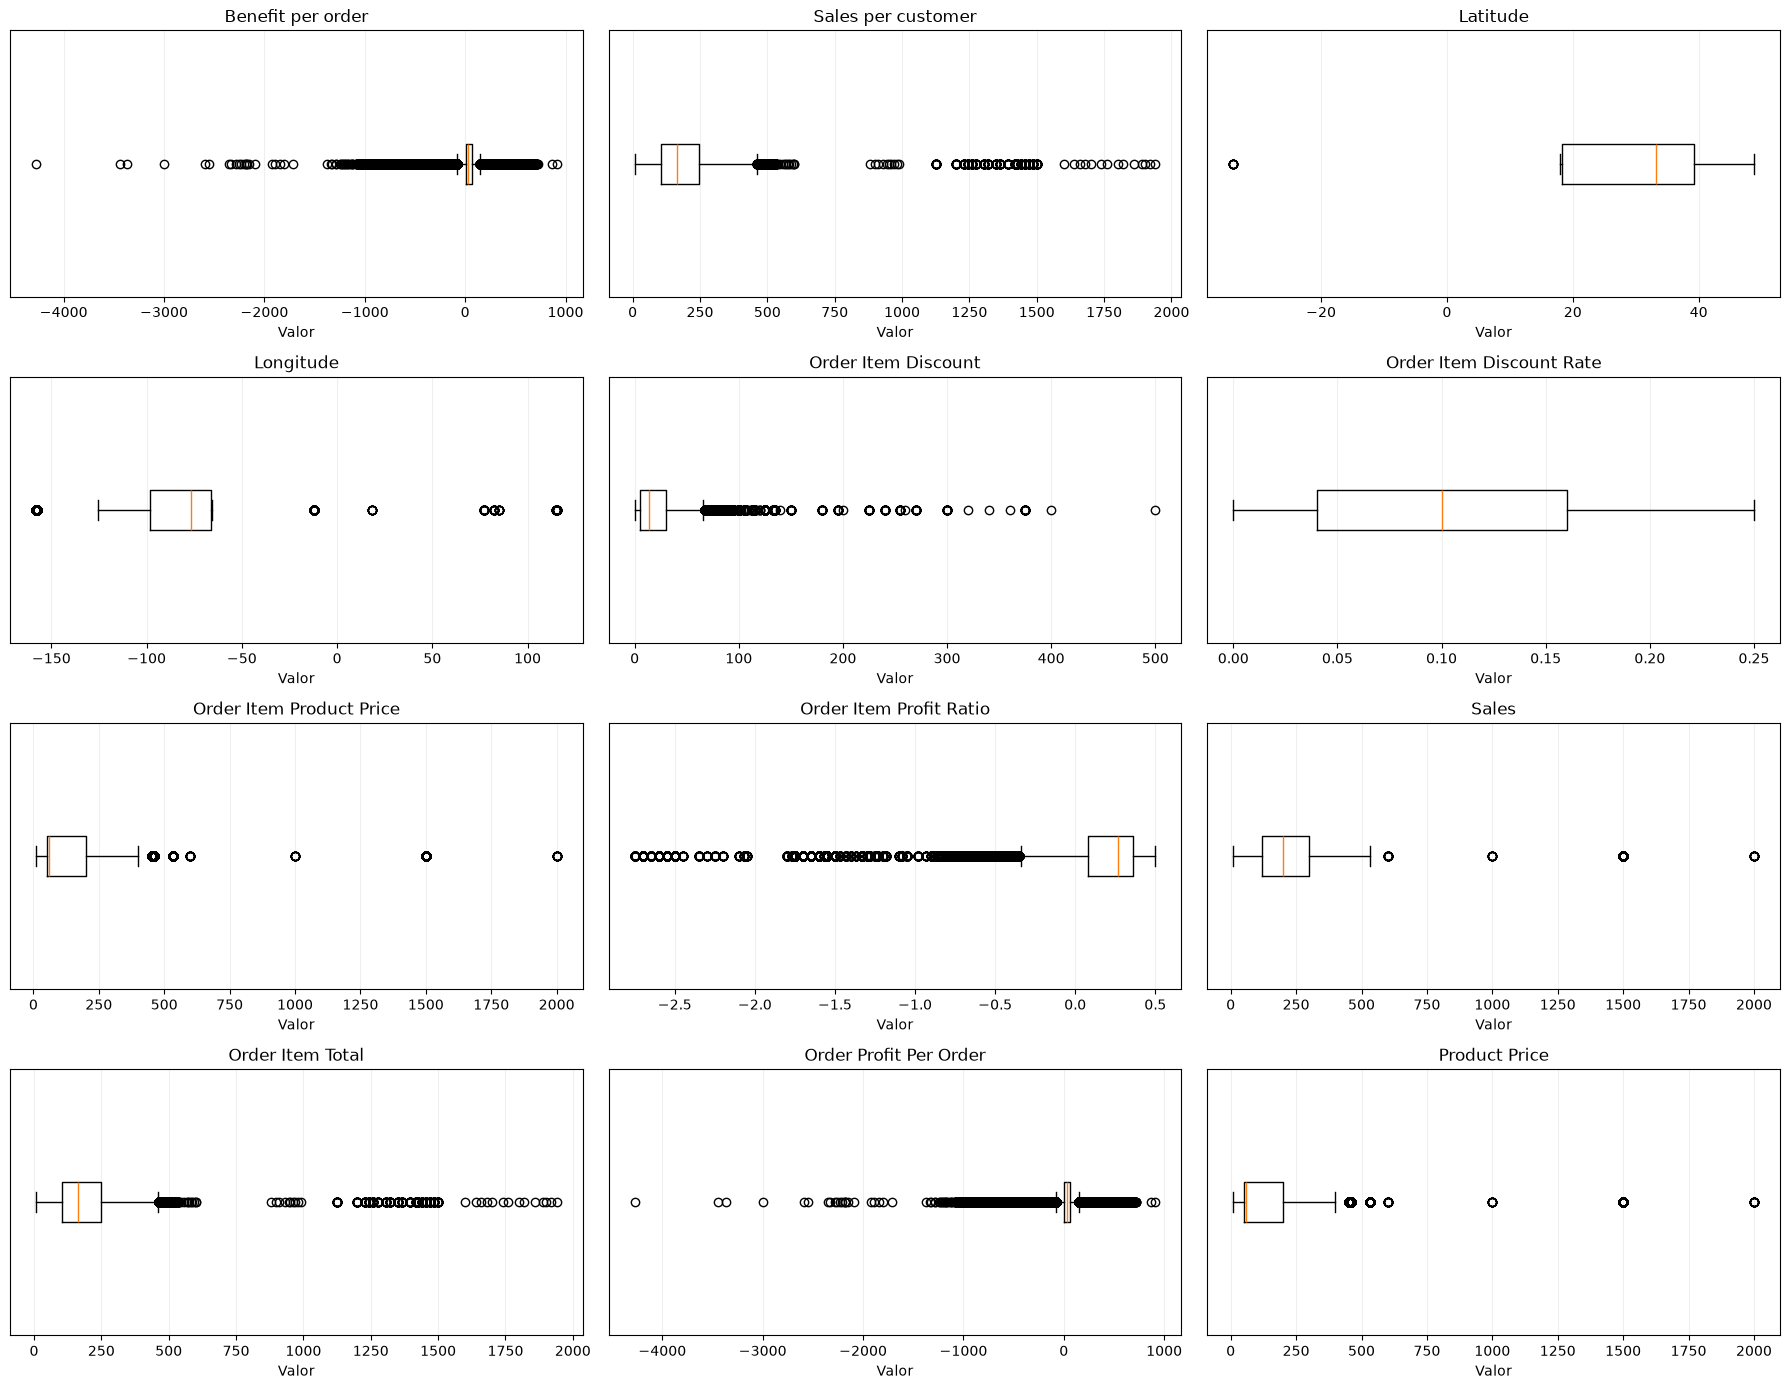

In [12]:

### 2.4 Diagramas de cajas y bigotes

fig, axes = plt.subplots(4, 3, figsize=(18, 14))

for ax, columna in zip(axes.flat, variables_continuas):
    valores = df[columna].dropna()

    ax.boxplot(valores, orientation="horizontal", showfliers=True)
    ax.set_title(columna)
    ax.set_yticks([])
    ax.set_xlabel("Valor")
    ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

### 2.5 Interpretación de los diagramas de cajas y bigotes

Los diagramas de cajas y bigotes permiten identificar diferencias en la dispersión de las variables numéricas, así como la presencia de posibles valores atípicos. Para su identificación se utiliza el criterio convencional de 1.5 veces el rango intercuartílico (RIC), representado mediante los límites de los bigotes.

**Ventas y precios:** Las variables `Sales`, `Sales per customer`, `Order Item Total`, `Product Price` y `Order Item Product Price` presentan observaciones por encima del bigote superior. Estas corresponden a importes considerablemente mayores que los valores centrales de sus respectivas distribuciones.

**Beneficios y rentabilidad:** Las variables `Benefit per order`, `Order Profit Per Order` y `Order Item Profit Ratio` presentan numerosos valores atípicos negativos, situados por debajo del bigote inferior. Destacan las pérdidas de gran magnitud, asociadas con distribuciones asimétricas hacia la izquierda.

**Descuentos:** `Order Item Discount` presenta valores atípicos elevados, mientras que `Order Item Discount Rate` mantiene sus observaciones dentro de los límites representados por los bigotes, sin valores atípicos visibles bajo el criterio utilizado.

**Coordenadas geográficas:** `Latitude` y `Longitude` presentan observaciones alejadas de sus intervalos centrales. Estas variables representan ubicaciones geográficas, por lo que los valores extremos deben interpretarse considerando su naturaleza espacial y no clasificarse automáticamente como errores.

En general, los diagramas evidencian valores extremos principalmente en variables monetarias y de rentabilidad. Su presencia no implica necesariamente errores en los datos, ya que pueden corresponder a operaciones comerciales válidas.

Por lo tanto, antes de aplicar métodos de eliminación o tratamiento de valores atípicos, resulta conveniente evaluar su comportamiento y considerar transformaciones que reduzcan la influencia de observaciones extremas durante el análisis.


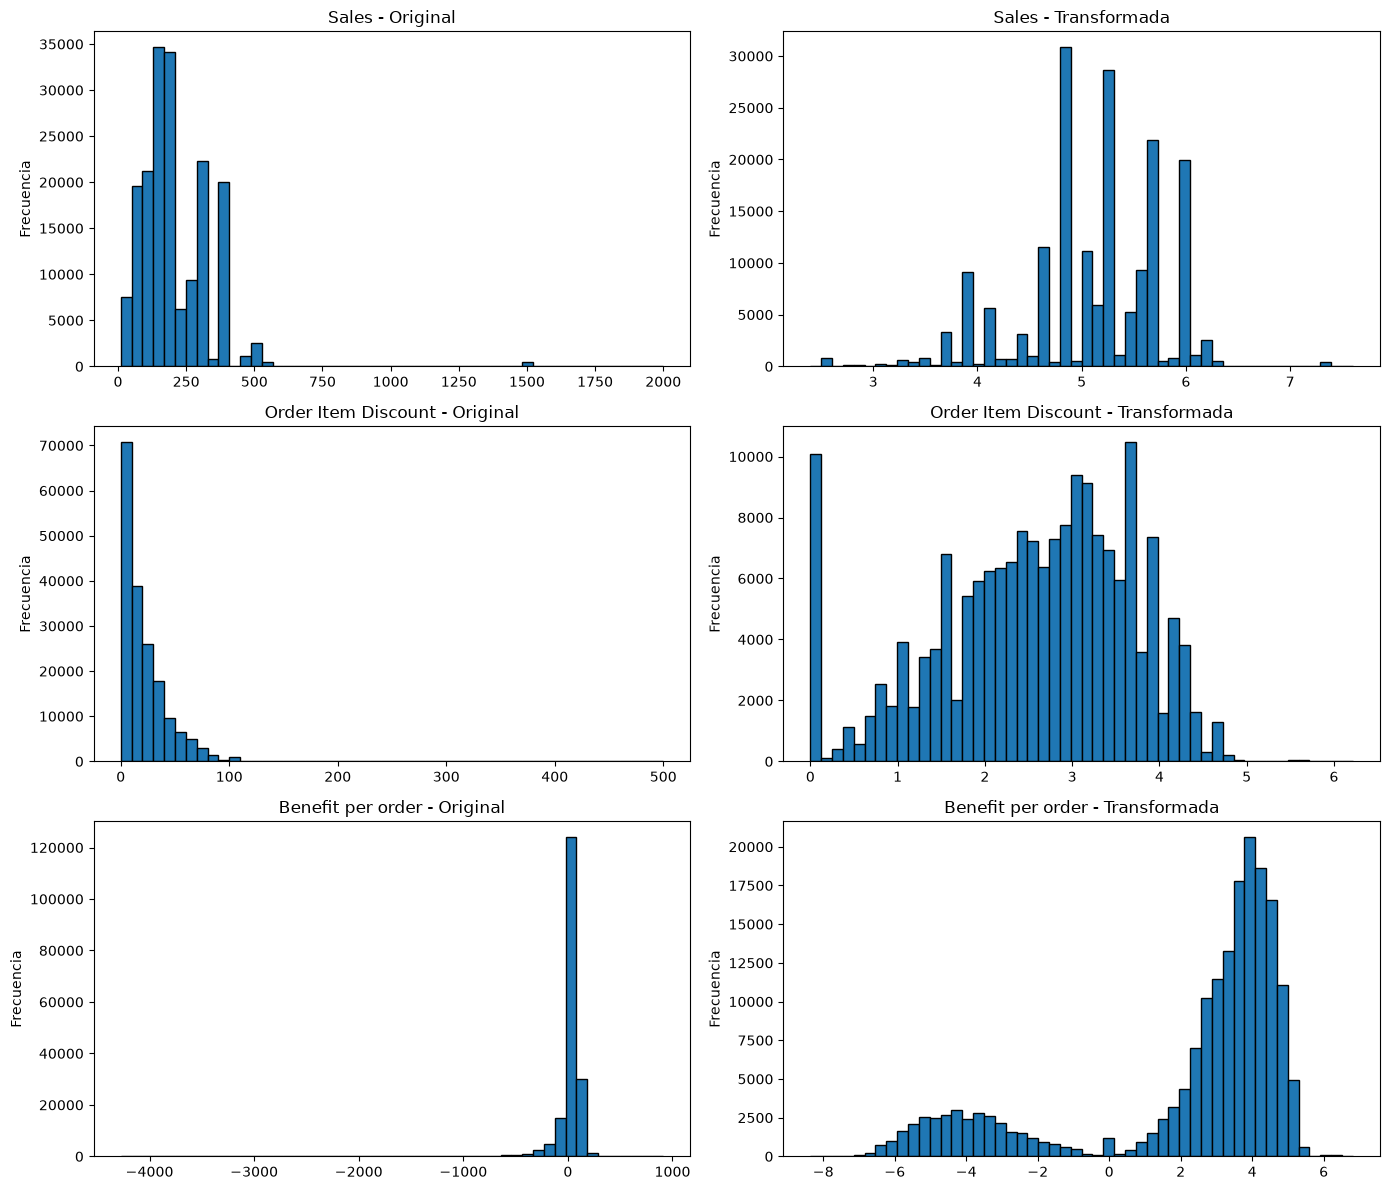

,Variable,Asimetría original,Asimetría transformada
0,Sales,2.8842,-0.6795
1,Order Item Discount,3.0398,-0.5240
2,Benefit per order,-4.7418,-1.4441


In [13]:

### 2.6 Comparación de distribuciones originales y transformadas

transformaciones = {
    "Sales": np.log1p(df["Sales"]),
    "Order Item Discount": np.log1p(df["Order Item Discount"]),
    "Benefit per order": (
        np.sign(df["Benefit per order"])
        * np.log1p(df["Benefit per order"].abs())
    )
}

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

resultados_transformaciones = []

for i, (variable, transformada) in enumerate(transformaciones.items()):
    original = df[variable]

    axes[i, 0].hist(original.dropna(), bins=50, edgecolor="black")
    axes[i, 0].set_title(f"{variable} - Original")
    axes[i, 0].set_ylabel("Frecuencia")

    axes[i, 1].hist(transformada.dropna(), bins=50, edgecolor="black")
    axes[i, 1].set_title(f"{variable} - Transformada")
    axes[i, 1].set_ylabel("Frecuencia")

    resultados_transformaciones.append({
        "Variable": variable,
        "Asimetría original": original.skew(),
        "Asimetría transformada": transformada.skew()
    })

plt.tight_layout()
plt.show()

comparacion_transformaciones = pd.DataFrame(
    resultados_transformaciones
)

display(comparacion_transformaciones.round(4))


### 2.7 Interpretación y evaluación de las transformaciones

Se evaluaron transformaciones logarítmicas sobre tres variables que presentaban asimetrías pronunciadas, comparando sus histogramas y coeficientes de asimetría antes y después de la transformación.

**Sales:** La asimetría pasó de 2.8842 a -0.6795. La transformación logarítmica redujo considerablemente la influencia de los valores elevados, aunque la distribución mantiene varios picos. Se considera una alternativa adecuada para evaluar durante el modelado.

**Order Item Discount:** La asimetría disminuyó de 3.0398 a -0.5240. La transformación permitió distribuir los valores de manera menos concentrada y reducir el efecto de los descuentos elevados. Se recomienda considerar esta transformación, conservando los valores iguales a cero mediante `log1p`.

**Benefit per order:** La transformación logarítmica con signo redujo la asimetría de -4.7418 a -1.4441. Aunque disminuyó la influencia de las pérdidas extremas, la distribución continúa siendo asimétrica y presenta agrupaciones diferenciadas. Por ello, también se considera conveniente evaluar alternativas como `RobustScaler`, que permite reducir la influencia de valores extremos durante el escalado.

Las transformaciones logarítmicas resultaron prometedoras para las variables monetarias con asimetría positiva. No obstante, una menor asimetría no garantiza un mejor desempeño predictivo. La selección definitiva de los tratamientos dependerá de los algoritmos utilizados y de su evaluación sobre los datos de entrenamiento.


## 3. Análisis de escalas y posibles tratamientos

En esta sección se comparan las escalas de las variables numéricas continuas identificadas previamente. El objetivo es reconocer diferencias de magnitud que puedan afectar a ciertos algoritmos de aprendizaje automático, documentar posibles tratamientos para etapas posteriores e identificar una variable adecuada para realizar una división estratificada de los datos.


In [14]:
### 3.1 Comparación de escalas de las variables continuas
variables_escala = [col for col in variables_continuas if col in df.columns]

resumen_escalas = pd.DataFrame({
    "Mínimo": df[variables_escala].min(),
    "Máximo": df[variables_escala].max(),
    "Media": df[variables_escala].mean(),
    "Desviación estándar": df[variables_escala].std(),
    "Q1": df[variables_escala].quantile(0.25),
    "Mediana": df[variables_escala].median(),
    "Q3": df[variables_escala].quantile(0.75),
    "Asimetría": df[variables_escala].skew()
})

resumen_escalas["Rango"] = resumen_escalas["Máximo"] - resumen_escalas["Mínimo"]
resumen_escalas["RIC"] = resumen_escalas["Q3"] - resumen_escalas["Q1"]

columnas_orden = [
    "Mínimo", "Máximo", "Rango", "Media", "Desviación estándar",
    "Q1", "Mediana", "Q3", "RIC", "Asimetría"
]

resumen_escalas = resumen_escalas[columnas_orden].sort_values(
    by="Rango",
    ascending=False
)

display(resumen_escalas.round(4))

,Mínimo,Máximo,Rango,Media,Desviación estándar,Q1,Mediana,Q3,RIC,Asimetría
Benefit per order,-4274.9800,911.8000,5186.7800,21.9750,104.4335,7.0000,31.5200,64.8000,57.8000,-4.7418
Order Profit Per Order,-4274.9800,911.8000,5186.7800,21.9750,104.4335,7.0000,31.5200,64.8000,57.8000,-4.7418
Order Item Product Price,9.9900,1999.9900,1990.0000,141.2325,139.7325,50.0000,59.9900,199.9900,149.9900,3.1910
Sales,9.9900,1999.9900,1990.0000,203.7721,132.2731,119.9800,199.9200,299.9500,179.9700,2.8842
Product Price,9.9900,1999.9900,1990.0000,141.2325,139.7325,50.0000,59.9900,199.9900,149.9900,3.1910
Order Item Total,7.4900,1939.9900,1932.5000,183.1076,120.0437,104.3800,163.9900,247.4000,143.0200,2.8884
Sales per customer,7.4900,1939.9900,1932.5000,183.1076,120.0437,104.3800,163.9900,247.4000,143.0200,2.8884
Order Item Discount,0.0000,500.0000,500.0000,20.6647,21.8009,5.4000,14.0000,29.9900,24.5900,3.0398
Longitude,-158.0260,115.2631,273.2891,-84.9157,21.4332,-98.4463,-76.8479,-66.3706,32.0757,-0.4985
Latitude,-33.9376,48.7819,82.7195,29.7200,9.8136,18.2654,33.1449,39.2796,21.0142,-0.0980


### 3.2 Interpretación de las escalas

La comparación permite observar que las variables analizadas no se encuentran en una escala homogénea. Las variables relacionadas con ventas, precios, descuentos y beneficios presentan magnitudes considerablemente mayores que las variables expresadas como tasas o proporciones. `Latitude` y `Longitude`, aunque también son numéricas, representan coordenadas geográficas y deben interpretarse de manera distinta a una medida monetaria.

Estas diferencias de escala no representan un problema para todos los algoritmos. Los modelos basados en árboles suelen ser poco sensibles a la magnitud de las variables, mientras que métodos basados en distancias, gradientes o regularización pueden verse afectados.

Por esta razón, cualquier escalado deberá aplicarse posteriormente dentro del proceso de preparación del modelo y ajustarse únicamente con el conjunto de entrenamiento, evitando fuga de información hacia el conjunto de prueba.

En los datos utilizados se observa claramente esta diferencia: `Order Item Discount Rate` varía entre 0 y 0.25, mientras que `Sales` y `Product Price` alcanzan valores de hasta 1 999.99. Por su parte, `Benefit per order` presenta valores desde -4 274.98 hasta 911.80.

Estos resultados confirman que las variables manejan rangos diferentes y justifican la evaluación de tratamientos específicos según el algoritmo que se utilice posteriormente.


In [15]:

### 3.3 Posibles tratamientos futuros

total_negativos = (df["Benefit per order"] < 0).sum()

tratamientos_futuros = pd.DataFrame([
    {
        "Grupo de variables": "Ventas, precios y descuentos monetarios",
        "Ejemplos": "Sales, Product Price, Order Item Total, Order Item Discount",
        "Tratamiento posible": "Transformación logarítmica, StandardScaler o RobustScaler",
        "Justificación": "Presentan diferencias de escala y valores extremos. Las transformaciones logarítmicas pueden reducir la asimetría positiva."
    },
    {
        "Grupo de variables": "Beneficio y utilidad",
        "Ejemplos": "Benefit per order, Order Profit Per Order",
        "Tratamiento posible": "Transformación logarítmica con signo o RobustScaler",
        "Justificación": f"Benefit per order contiene {total_negativos:,} valores negativos. La transformación con signo permite conservarlos y reducir la magnitud de valores extremos."
    },
    {
        "Grupo de variables": "Tasas y razones",
        "Ejemplos": "Order Item Discount Rate, Order Item Profit Ratio",
        "Tratamiento posible": "Mantener o estandarizar según el algoritmo",
        "Justificación": "Presentan escalas relativamente acotadas. El escalado puede ser innecesario para modelos basados en árboles."
    },
    {
        "Grupo de variables": "Coordenadas geográficas",
        "Ejemplos": "Latitude, Longitude",
        "Tratamiento posible": "Mantener o realizar ingeniería de características geográficas",
        "Justificación": "Representan ubicaciones y requieren una interpretación diferente a las variables monetarias."
    },
    {
        "Grupo de variables": "Códigos postales",
        "Ejemplos": "Customer Zipcode, Order Zipcode",
        "Tratamiento posible": "Tratar como identificadores geográficos",
        "Justificación": "Aunque se almacenan numéricamente, representan códigos de ubicación y no magnitudes continuas."
    },
    {
        "Grupo de variables": "Variables sin información útil o constantes",
        "Ejemplos": "Product Description, Product Status",
        "Tratamiento posible": "Evaluar su eliminación",
        "Justificación": "Product Description contiene únicamente valores faltantes y Product Status presenta un valor constante."
    },
    {
        "Grupo de variables": "Variables potencialmente redundantes",
        "Ejemplos": "Benefit per order / Order Profit Per Order; Sales per customer / Order Item Total; Product Price / Order Item Product Price",
        "Tratamiento posible": "Verificar igualdad y evaluar la conservación de una variable por par",
        "Justificación": "Las estadísticas descriptivas coinciden entre los pares señalados. Se requiere comprobar la igualdad registro por registro."
    },
    {
        "Grupo de variables": "Variable objetivo",
        "Ejemplos": "Late_delivery_risk",
        "Tratamiento posible": "Mantener como variable binaria 0/1",
        "Justificación": "Es la variable que se desea predecir y no requiere normalización ni estandarización."
    }
])

display(tratamientos_futuros)

pares_variables = [
    ("Benefit per order", "Order Profit Per Order"),
    ("Sales per customer", "Order Item Total"),
    ("Product Price", "Order Item Product Price")
]

comprobacion_redundancias = pd.DataFrame([
    {
        "Variable 1": variable_1,
        "Variable 2": variable_2,
        "Valores idénticos": df[variable_1].equals(df[variable_2])
    }
    for variable_1, variable_2 in pares_variables
])

display(comprobacion_redundancias)

,Grupo de variables,Ejemplos,Tratamiento posible,Justificación
0,"Ventas, precios y descuentos monetarios","Sales, Product Price, Order Item Total, Order ...","Transformación logarítmica, StandardScaler o R...",Presentan diferencias de escala y valores extr...
1,Beneficio y utilidad,"Benefit per order, Order Profit Per Order",Transformación logarítmica con signo o RobustS...,"Benefit per order contiene 33,784 valores nega..."
2,Tasas y razones,"Order Item Discount Rate, Order Item Profit Ratio",Mantener o estandarizar según el algoritmo,Presentan escalas relativamente acotadas. El e...
3,Coordenadas geográficas,"Latitude, Longitude",Mantener o realizar ingeniería de característi...,Representan ubicaciones y requieren una interp...
4,Códigos postales,"Customer Zipcode, Order Zipcode",Tratar como identificadores geográficos,"Aunque se almacenan numéricamente, representan..."
5,Variables sin información útil o constantes,"Product Description, Product Status",Evaluar su eliminación,Product Description contiene únicamente valore...
6,Variables potencialmente redundantes,Benefit per order / Order Profit Per Order; Sa...,Verificar igualdad y evaluar la conservación d...,Las estadísticas descriptivas coinciden entre ...
7,Variable objetivo,Late_delivery_risk,Mantener como variable binaria 0/1,Es la variable que se desea predecir y no requ...


,Variable 1,Variable 2,Valores idénticos
0,Benefit per order,Order Profit Per Order,True
1,Sales per customer,Order Item Total,True
2,Product Price,Order Item Product Price,True


In [16]:
### 3.4 Variable seleccionada para estratificación
variable_estratificacion = "Shipping Mode"

frecuencias = df[variable_estratificacion].value_counts()

resumen_estratificacion = pd.DataFrame({
    "Cantidad": frecuencias,
    "Porcentaje (%)": (
        df[variable_estratificacion]
        .value_counts(normalize=True) * 100
    ).round(2)
})

display(resumen_estratificacion)

,Cantidad,Porcentaje (%)
Shipping Mode,,
Standard Class,107752,59.69
Second Class,35216,19.51
First Class,27814,15.41
Same Day,9737,5.39


### 3.5 Variable seleccionada para la estratificación

Se seleccionó `Shipping Mode` como variable de estratificación, ya que representa una característica predictiva categórica relacionada con la modalidad de envío.

Esta variable contiene cuatro categorías: Standard Class (59.69 %), Second Class (19.51 %), First Class (15.41 %) y Same Day (5.39 %). Todas cuentan con suficientes registros para realizar una división estratificada.

La estratificación permitirá conservar aproximadamente estas proporciones en los conjuntos de entrenamiento y prueba, evitando diferencias de representación entre las modalidades de envío.


## 4. Conjuntos de entrenamiento y prueba

Se realizaron dos divisiones del conjunto de datos, utilizando un 80 % para entrenamiento y un 20 % para prueba. La primera división se efectuó mediante muestreo aleatorio y la segunda mediante estratificación utilizando la variable predictiva `Shipping Mode`.

Ambas divisiones emplearon la misma semilla (`random_state=42`) para garantizar la reproducibilidad.

Posteriormente, se compararon las proporciones de las modalidades de envío y sus desviaciones respecto a la distribución original, con el propósito de determinar cuál estrategia conserva mejor la representación de las categorías.


In [17]:
### 4.1 Preparación de X e y
from sklearn.model_selection import train_test_split

variable_objetivo = "Late_delivery_risk"

X = df.drop(columns=[variable_objetivo])
y = df[variable_objetivo]

print(f"Registros totales: {len(df):,}")
print(f"Variables predictoras antes de la selección final: {X.shape[1]}")
print(f"Variable objetivo: {variable_objetivo}")

Registros totales: 180,519
Variables predictoras antes de la selección final: 43
Variable objetivo: Late_delivery_risk


In [18]:
### 4.2 División aleatoria
X_train_aleatorio, X_test_aleatorio, y_train_aleatorio, y_test_aleatorio = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print(f"Entrenamiento aleatorio: {len(X_train_aleatorio):,} registros ({len(X_train_aleatorio) / len(df) * 100:.2f}%)")
print(f"Prueba aleatoria:        {len(X_test_aleatorio):,} registros ({len(X_test_aleatorio) / len(df) * 100:.2f}%)")

Entrenamiento aleatorio: 144,415 registros (80.00%)
Prueba aleatoria:        36,104 registros (20.00%)


In [19]:
### 4.3 División estratificada
X_train_estratificado, X_test_estratificado, y_train_estratificado, y_test_estratificado = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=X["Shipping Mode"]
)

print(f"Entrenamiento estratificado: {len(X_train_estratificado):,} registros ({len(X_train_estratificado) / len(df) * 100:.2f}%)")
print(f"Prueba estratificada:        {len(X_test_estratificado):,} registros ({len(X_test_estratificado) / len(df) * 100:.2f}%)")

Entrenamiento estratificado: 144,415 registros (80.00%)
Prueba estratificada:        36,104 registros (20.00%)


In [20]:

### 4.4 Comparación de proporciones

categorias = sorted(df["Shipping Mode"].dropna().unique())

def obtener_proporciones(serie):
    return (
        serie.value_counts(normalize=True)
        .reindex(categorias, fill_value=0)
    )

proporciones = pd.DataFrame({
    "Conjunto original": obtener_proporciones(df["Shipping Mode"]),
    "Train aleatorio": obtener_proporciones(X_train_aleatorio["Shipping Mode"]),
    "Test aleatorio": obtener_proporciones(X_test_aleatorio["Shipping Mode"]),
    "Train estratificado": obtener_proporciones(X_train_estratificado["Shipping Mode"]),
    "Test estratificado": obtener_proporciones(X_test_estratificado["Shipping Mode"])
}).T * 100

proporciones.columns = [
    f"{categoria} (%)" for categoria in proporciones.columns
]

display(proporciones.round(4))

,First Class (%),Same Day (%),Second Class (%),Standard Class (%)
Conjunto original,15.4078,5.3939,19.5082,59.6901
Train aleatorio,15.4298,5.3845,19.5201,59.6655
Test aleatorio,15.3196,5.4315,19.4604,59.7884
Train estratificado,15.4077,5.3942,19.5084,59.6898
Test estratificado,15.4083,5.3928,19.5075,59.6914


In [21]:

### 4.5 Error de muestreo respecto a la distribución original

proporcion_original = proporciones.loc["Conjunto original"]

conjuntos_comparacion = [
    "Train aleatorio",
    "Test aleatorio",
    "Train estratificado",
    "Test estratificado"
]

diferencias = (
    proporciones.loc[conjuntos_comparacion]
    .sub(proporcion_original, axis="columns")
    .abs()
)

comparacion_error = pd.DataFrame({
    "Error promedio (p.p.)": diferencias.mean(axis=1),
    "Error máximo (p.p.)": diferencias.max(axis=1)
})

display(comparacion_error.round(6))

,Error promedio (p.p.),Error máximo (p.p.)
Train aleatorio,0.016989,0.024569
Test aleatorio,0.067956,0.098273
Train estratificado,0.000225,0.000333
Test estratificado,0.000900,0.001331


In [22]:

### 4.6 Comparación automática de ambas estrategias

error_test_aleatorio = comparacion_error.loc[
    "Test aleatorio", "Error promedio (p.p.)"
]

error_test_estratificado = comparacion_error.loc[
    "Test estratificado", "Error promedio (p.p.)"
]

print(f"Error promedio del conjunto de prueba aleatorio: {error_test_aleatorio:.6f} puntos porcentuales")
print(f"Error promedio del conjunto de prueba estratificado: {error_test_estratificado:.6f} puntos porcentuales")

if error_test_estratificado < error_test_aleatorio:
    print("La división estratificada conserva mejor la distribución de Shipping Mode.")
elif error_test_estratificado > error_test_aleatorio:
    print("La división aleatoria presenta un menor error de muestreo.")
else:
    print("Ambas estrategias presentan el mismo error promedio de muestreo.")

Error promedio del conjunto de prueba aleatorio: 0.067956 puntos porcentuales
Error promedio del conjunto de prueba estratificado: 0.000900 puntos porcentuales
La división estratificada conserva mejor la distribución de Shipping Mode.


### 4.7 Conclusión de la comparación

Se realizaron dos divisiones del conjunto de datos, utilizando un 80 % para entrenamiento y un 20 % para prueba. La primera división fue aleatoria, mientras que la segunda utilizó estratificación mediante la variable predictiva `Shipping Mode`.

Los resultados muestran que la división aleatoria conserva proporciones cercanas a las originales, aunque presenta pequeñas variaciones entre las modalidades de envío. El conjunto de prueba aleatorio obtuvo un error promedio de 0.067956 puntos porcentuales y un error máximo de 0.098273 puntos porcentuales.

Por su parte, el conjunto de prueba estratificado presentó un error promedio de 0.000900 puntos porcentuales y un error máximo de 0.001331 puntos porcentuales, conservando con mayor precisión la distribución original de las cuatro modalidades de envío.

Por lo tanto, se selecciona la división estratificada como estrategia para continuar con el proyecto, dado que garantiza una representación proporcional de las categorías de `Shipping Mode` en los conjuntos de entrenamiento y prueba.


### 5. Correlaciones y construcción de atributos

Esta sección continúa el análisis utilizando únicamente el conjunto de entrenamiento estratificado. Se estudian correlaciones lineales mediante Pearson y relaciones no necesariamente lineales mediante correlación de distancia. Posteriormente se construyen atributos derivados (ratios) con sentido para el problema y se evalúa si aportan una relación adicional con la variable objetivo Late_delivery_risk.

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

variable_objetivo = "Late_delivery_risk"

if "df" not in globals():
    rutas_posibles = [
        "Dataset/DataCoSupplyChainDataset.csv",
        "DataCoSupplyChainDataset.csv",
        "/mnt/data/DataCoSupplyChainDataset.csv"
    ]

    ruta_encontrada = next((ruta for ruta in rutas_posibles if Path(ruta).exists()), None)

    if ruta_encontrada is None:
        raise FileNotFoundError(
            "No se encontró DataCoSupplyChainDataset.csv. "
            "Colóquelo en Dataset/ o en la misma carpeta del notebook."
        )

    df = pd.read_csv(ruta_encontrada, encoding="latin1", sep=";")

if "X_train_estratificado" not in globals() or "y_train_estratificado" not in globals():
    from sklearn.model_selection import train_test_split

    X = df.drop(columns=[variable_objetivo])
    y = df[variable_objetivo]

    X_train_estratificado, X_test_estratificado, y_train_estratificado, y_test_estratificado = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=X["Shipping Mode"]
    )

df_train_analisis = X_train_estratificado.copy()
df_train_analisis[variable_objetivo] = y_train_estratificado

print(f"Registros utilizados para el análisis: {len(df_train_analisis):,}")
print(f"Registros reservados para prueba: {len(X_test_estratificado):,}")
print("El conjunto de prueba no se utiliza en esta sección.")

Registros utilizados para el análisis: 144,415
Registros reservados para prueba: 36,104
El conjunto de prueba no se utiliza en esta sección.


### 5.2 Variables consideradas 
Para las correlaciones se parte de las variables continuas identificadas previamente. Además, se incorpora Days for shipment (scheduled) porque, aunque toma valores enteros, representa una magnitud numérica operacional disponible al registrar el pedido y resulta relevante para estudiar el riesgo de retraso.

No se utiliza Days for shipping (real) como predictor, ya que representa el tiempo real observado después del envío y, por tanto, produciría fuga de información si se empleara para predecir un retraso antes de que ocurra.

In [24]:
if "variables_continuas" not in globals():
    variables_continuas = [
        "Benefit per order",
        "Sales per customer",
        "Latitude",
        "Longitude",
        "Order Item Discount",
        "Order Item Discount Rate",
        "Order Item Product Price",
        "Order Item Profit Ratio",
        "Sales",
        "Order Item Total",
        "Order Profit Per Order",
        "Product Price"
    ]

variables_pearson = (
    ["Days for shipment (scheduled)"]
    + [col for col in variables_continuas if col in df_train_analisis.columns]
)

print(f"Variables numéricas analizadas: {len(variables_pearson)}")
variables_pearson

Variables numéricas analizadas: 13


['Days for shipment (scheduled)',
 'Benefit per order',
 'Sales per customer',
 'Latitude',
 'Longitude',
 'Order Item Discount',
 'Order Item Discount Rate',
 'Order Item Product Price',
 'Order Item Profit Ratio',
 'Sales',
 'Order Item Total',
 'Order Profit Per Order',
 'Product Price']

### 5.3 Correlación de Pearson entre variables numéricas
El coeficiente de Pearson permite medir relaciones lineales. Sus valores se encuentran entre -1 y 1. Los valores cercanos a 1 o -1 indican una relación lineal fuerte, mientras que los valores cercanos a 0 indican una relación lineal débil.

Debido a que Late_delivery_risk es binaria (0/1), su correlación de Pearson con una variable numérica es equivalente a una correlación punto-biserial, por lo que puede utilizarse como una primera medida descriptiva de asociación.

In [25]:
columnas_pearson = variables_pearson + [variable_objetivo]

matriz_pearson = (
    df_train_analisis[columnas_pearson]
    .corr(method="pearson")
)

display(matriz_pearson.round(4))

,Days for shipment (scheduled),Benefit per order,Sales per customer,Latitude,Longitude,Order Item Discount,Order Item Discount Rate,Order Item Product Price,Order Item Profit Ratio,Sales,Order Item Total,Order Profit Per Order,Product Price,Late_delivery_risk
Days for shipment (scheduled),1.0000,-0.0005,0.0066,-0.0058,0.0043,0.0023,-0.0017,0.0073,-0.0022,0.0064,0.0066,-0.0005,0.0073,-0.3699
Benefit per order,-0.0005,1.0000,0.1415,0.0009,-0.0033,0.0694,-0.0183,0.1120,0.8291,0.1398,0.1415,1.0000,0.1120,-0.0026
Sales per customer,0.0066,0.1415,1.0000,-0.0002,0.0008,0.5023,-0.1181,0.7797,-0.0001,0.9897,1.0000,0.1415,0.7797,-0.0039
Latitude,-0.0058,0.0009,-0.0002,1.0000,-0.5235,-0.0043,-0.0057,-0.0001,-0.0005,-0.0009,-0.0002,0.0009,-0.0001,0.0018
Longitude,0.0043,-0.0033,0.0008,-0.5235,1.0000,0.0034,0.0012,-0.0004,-0.0038,0.0013,0.0008,-0.0033,-0.0004,-0.0019
Order Item Discount,0.0023,0.0694,0.5023,-0.0043,0.0034,1.0000,0.6590,0.4914,-0.0018,0.6208,0.5023,0.0694,0.4914,-0.0021
Order Item Discount Rate,-0.0017,-0.0183,-0.1181,-0.0057,0.0012,0.6590,1.0000,0.0024,-0.0017,0.0019,-0.1181,-0.0183,0.0024,-0.0002
Order Item Product Price,0.0073,0.1120,0.7797,-0.0001,-0.0004,0.4914,0.0024,1.0000,0.0002,0.7881,0.7797,0.1120,1.0000,-0.0033
Order Item Profit Ratio,-0.0022,0.8291,-0.0001,-0.0005,-0.0038,-0.0018,-0.0017,0.0002,1.0000,-0.0003,-0.0001,0.8291,0.0002,-0.0008
Sales,0.0064,0.1398,0.9897,-0.0009,0.0013,0.6208,0.0019,0.7881,-0.0003,1.0000,0.9897,0.1398,0.7881,-0.0039


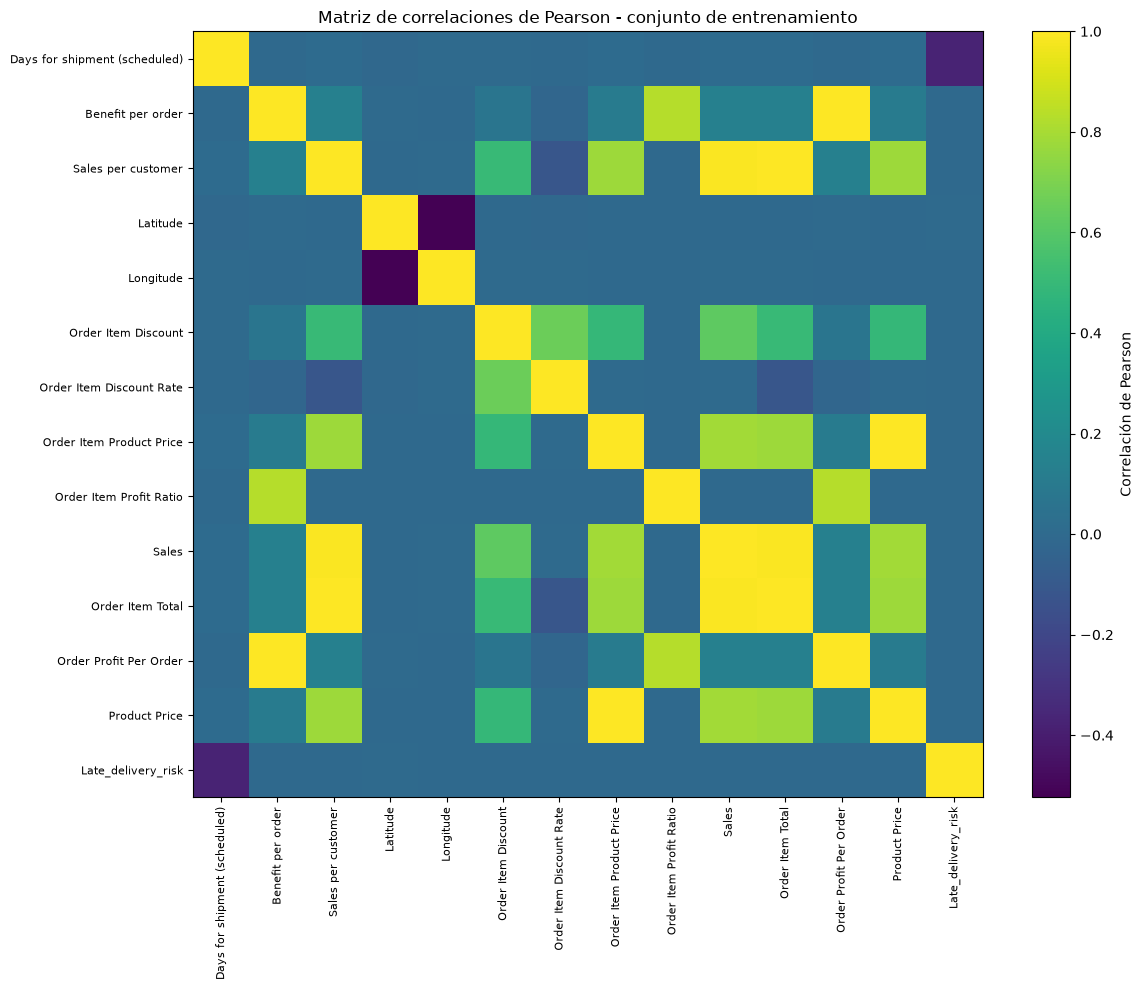

In [26]:
# Mapa de calor de Pearson

fig, ax = plt.subplots(figsize=(12, 10))
imagen = ax.imshow(matriz_pearson.values, aspect="auto")

ax.set_xticks(range(len(matriz_pearson.columns)))
ax.set_xticklabels(matriz_pearson.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(matriz_pearson.index)))
ax.set_yticklabels(matriz_pearson.index, fontsize=8)

fig.colorbar(imagen, ax=ax, label="Correlación de Pearson")
ax.set_title("Matriz de correlaciones de Pearson - conjunto de entrenamiento")
plt.tight_layout()
plt.show()

In [27]:
# Correlaciones de las variables numéricas con la variable objetivo

correlacion_objetivo_pearson = (
    matriz_pearson[variable_objetivo]
    .drop(variable_objetivo)
    .sort_values(key=lambda serie: serie.abs(), ascending=False)
    .to_frame("Pearson con Late_delivery_risk")
)

display(correlacion_objetivo_pearson.round(4))

,Pearson con Late_delivery_risk
Days for shipment (scheduled),-0.3699
Sales per customer,-0.0039
Order Item Total,-0.0039
Sales,-0.0039
Order Item Product Price,-0.0033
Product Price,-0.0033
Order Profit Per Order,-0.0026
Benefit per order,-0.0026
Order Item Discount,-0.0021
Longitude,-0.0019


In [28]:
pares_correlacionados = []

for i, variable_a in enumerate(variables_pearson):
    for variable_b in variables_pearson[i + 1:]:
        r = matriz_pearson.loc[variable_a, variable_b]
        if abs(r) >= 0.80:
            pares_correlacionados.append({
                "Variable 1": variable_a,
                "Variable 2": variable_b,
                "Pearson": r
            })

tabla_pares = pd.DataFrame(pares_correlacionados)

if not tabla_pares.empty:
    tabla_pares["|Pearson|"] = tabla_pares["Pearson"].abs()
    tabla_pares = tabla_pares.sort_values("|Pearson|", ascending=False)
    display(tabla_pares.round(4))
else:
    print("No se encontraron pares con |Pearson| >= 0.80.")

,Variable 1,Variable 2,Pearson,|Pearson|
1,Benefit per order,Order Profit Per Order,1.0000,1.0000
4,Order Item Product Price,Product Price,1.0000,1.0000
3,Sales per customer,Order Item Total,1.0000,1.0000
6,Sales,Order Item Total,0.9897,0.9897
2,Sales per customer,Sales,0.9897,0.9897
0,Benefit per order,Order Item Profit Ratio,0.8291,0.8291
5,Order Item Profit Ratio,Order Profit Per Order,0.8291,0.8291


### Interpretación de Pearson
La variable numérica que presenta la relación lineal más clara con Late_delivery_risk es Days for shipment (scheduled). La correlación es negativa: a mayor cantidad de días programados para realizar el envío, el riesgo histórico de entrega tardía tiende a disminuir.

Las variables monetarias y geográficas muestran correlaciones lineales muy pequeñas con la variable objetivo. Esto no significa que deban eliminarse: una correlación de Pearson baja solamente indica que no se observa una relación lineal importante de manera individual.

La matriz también permite detectar redundancias. En particular, existen pares de columnas con correlación perfecta o casi perfecta. Estos casos deben documentarse para revisarlos posteriormente durante la selección de atributos, sin eliminarlos todavía en esta etapa exploratoria.

### 5.4 Verificación de una variable con fuga de información
Days for shipping (real) se analiza únicamente como comprobación histórica. No debe considerarse un predictor válido para el modelo final porque su valor se conoce después de que el proceso de envío ha ocurrido.

In [29]:
correlacion_fuga = (
    df_train_analisis[
        ["Days for shipping (real)", "Days for shipment (scheduled)", variable_objetivo]
    ]
    .corr()[variable_objetivo]
    .drop(variable_objetivo)
    .to_frame("Pearson con Late_delivery_risk")
)

correlacion_fuga["Uso como predictor"] = [
    "NO - información posterior al envío",
    "SÍ - información disponible al registrar el pedido"
]

display(correlacion_fuga.round(4))

,Pearson con Late_delivery_risk,Uso como predictor
Days for shipping (real),0.4012,NO - información posterior al envío
Days for shipment (scheduled),-0.3699,SÍ - información disponible al registrar el pe...


### 5.5 Correlación de distancia
La correlación de distancia permite detectar asociaciones que no necesariamente son lineales. Sus valores se encuentran entre 0 y 1: valores cercanos a 1 representan una dependencia más fuerte y valores cercanos a 0 representan una dependencia débil.

El cálculo exacto de correlación de distancia puede ser costoso para más de 144 mil registros porque utiliza distancias entre pares de observaciones. Por esta razón se utiliza una muestra reproducible de 2,000 registros del conjunto de entrenamiento. Esto mantiene el análisis en el conjunto de entrenamiento y evita utilizar información del test.

El código intenta utilizar la biblioteca dcor si está instalada. Si no lo está, emplea una implementación equivalente con NumPy.

In [30]:
try:
    import dcor
    _usar_dcor = True
    print("Se utilizará la biblioteca dcor.")
except ImportError:
    _usar_dcor = False
    print("dcor no está instalada; se utilizará la implementación NumPy incluida.")

def correlacion_distancia_numpy(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    a = np.abs(x[:, None] - x[None, :])
    b = np.abs(y[:, None] - y[None, :])

    A = a - a.mean(axis=0)[None, :] - a.mean(axis=1)[:, None] + a.mean()
    B = b - b.mean(axis=0)[None, :] - b.mean(axis=1)[:, None] + b.mean()

    dcov2 = np.mean(A * B)
    dvar_x2 = np.mean(A * A)
    dvar_y2 = np.mean(B * B)

    if dvar_x2 <= 0 or dvar_y2 <= 0:
        return np.nan

    return np.sqrt(max(dcov2, 0) / np.sqrt(dvar_x2 * dvar_y2))

def calcular_correlacion_distancia(x, y):
    if _usar_dcor:
        return float(dcor.distance_correlation(
            np.asarray(x, dtype=float),
            np.asarray(y, dtype=float)
        ))
    return correlacion_distancia_numpy(x, y)

columnas_distancia = variables_pearson + [variable_objetivo]

muestra_distancia = (
    df_train_analisis[columnas_distancia]
    .dropna()
    .sample(n=min(2000, len(df_train_analisis)), random_state=42)
)

resultados_distancia = {}

for columna in variables_pearson:
    resultados_distancia[columna] = calcular_correlacion_distancia(
        muestra_distancia[columna].values,
        muestra_distancia[variable_objetivo].values
    )

tabla_distancia = (
    pd.Series(resultados_distancia, name="Correlación de distancia")
    .sort_values(ascending=False)
    .to_frame()
)

display(tabla_distancia.round(4))

dcor no está instalada; se utilizará la implementación NumPy incluida.


,Correlación de distancia
Days for shipment (scheduled),0.4001
Order Item Profit Ratio,0.0615
Benefit per order,0.0499
Order Profit Per Order,0.0499
Longitude,0.0319
Product Price,0.0254
Order Item Product Price,0.0254
Order Item Discount Rate,0.0226
Latitude,0.0215
Sales per customer,0.0199


###* Interpretación de la correlación de distancia
Days for shipment (scheduled) vuelve a destacar claramente sobre las demás variables numéricas. Esto refuerza la idea de que el plazo programado de envío contiene información útil relacionada con el riesgo de retraso.

Algunas variables económicas presentan una correlación de distancia ligeramente mayor que su correlación de Pearson, lo cual sugiere que podría existir alguna asociación no lineal débil. Sin embargo, sus valores siguen siendo reducidos, por lo que no se consideran individualmente predictores fuertes en esta etapa.

No se elimina ninguna variable únicamente por presentar una correlación baja. La utilidad definitiva se evaluará posteriormente mediante los modelos predictivos.

### 5.6 Variables relacionadas con la variable objetivo
A continuación se comparan las dos medidas utilizadas. Esto permite distinguir variables con una relación lineal evidente de aquellas que podrían presentar alguna dependencia no lineal.

In [31]:
resumen_relacion_objetivo = pd.concat(
    [
        correlacion_objetivo_pearson,
        tabla_distancia
    ],
    axis=1
)

resumen_relacion_objetivo["|Pearson|"] = (
    resumen_relacion_objetivo["Pearson con Late_delivery_risk"].abs()
)

resumen_relacion_objetivo = resumen_relacion_objetivo.sort_values(
    ["|Pearson|", "Correlación de distancia"],
    ascending=False
)

display(resumen_relacion_objetivo.round(4))

,Pearson con Late_delivery_risk,Correlación de distancia,|Pearson|
Days for shipment (scheduled),-0.3699,0.4001,0.3699
Sales per customer,-0.0039,0.0199,0.0039
Order Item Total,-0.0039,0.0199,0.0039
Sales,-0.0039,0.0123,0.0039
Order Item Product Price,-0.0033,0.0254,0.0033
Product Price,-0.0033,0.0254,0.0033
Order Profit Per Order,-0.0026,0.0499,0.0026
Benefit per order,-0.0026,0.0499,0.0026
Order Item Discount,-0.0021,0.0175,0.0021
Longitude,-0.0019,0.0319,0.0019


Days for shipment (scheduled) es el predictor numérico individual más destacado en este análisis. Presenta una correlación de Pearson moderada y negativa con el riesgo de retraso, y también la mayor correlación de distancia.
Days for shipping (real) no se utilizará como predictor, aunque históricamente se relaciona con Late_delivery_risk, porque constituye información posterior al proceso de envío.
Las variables monetarias, descuentos, ganancias y coordenadas presentan asociaciones individuales débiles con la variable objetivo. Esto no implica que sean inútiles, ya que un modelo puede descubrir interacciones que una correlación individual no refleja.
Existen variables redundantes o casi redundantes, lo cual se observa mediante correlaciones muy altas entre algunas columnas. Estos pares se revisarán más adelante durante la selección de atributos.
Las variables categóricas no se evalúan con Pearson en esta sección. Por ejemplo, Shipping Mode deberá tratarse mediante técnicas adecuadas para datos categóricos antes de incorporarse al modelado.

### 5.7 Creación de atributos derivados (ratios)
Se crean tres atributos con interpretación operacional a partir de variables existentes:
- Discount_per_item: descuento monetario promedio aplicado por unidad del artículo.
- Profit_per_item: beneficio promedio obtenido por unidad del artículo.
- Net_revenue_per_item: ingreso neto promedio por unidad después de descuentos.
Se conserva la información original; estos atributos se agregan únicamente para evaluar si expresan mejor alguna relación con el riesgo de entrega tardía.

In [32]:
df_train_atributos = df_train_analisis.copy()

cantidad_segura = df_train_atributos["Order Item Quantity"].replace(0, np.nan)

df_train_atributos["Discount_per_item"] = (
    df_train_atributos["Order Item Discount"] / cantidad_segura
)

df_train_atributos["Profit_per_item"] = (
    df_train_atributos["Benefit per order"] / cantidad_segura
)

df_train_atributos["Net_revenue_per_item"] = (
    df_train_atributos["Order Item Total"] / cantidad_segura
)

atributos_nuevos = [
    "Discount_per_item",
    "Profit_per_item",
    "Net_revenue_per_item"
]

display(
    df_train_atributos[
        [
            "Order Item Quantity",
            "Order Item Discount",
            "Benefit per order",
            "Order Item Total"
        ] + atributos_nuevos
    ].head()
)

,Order Item Quantity,Order Item Discount,Benefit per order,Order Item Total,Discount_per_item,Profit_per_item,Net_revenue_per_item
32071,3,8.99,-57.560001,35.980000,2.996667,-19.186667,11.993333
83230,1,1.30,63.060001,128.690002,1.300000,63.060001,128.690002
164640,4,26.00,13.050000,174.000000,6.500000,3.262500,43.500000
118015,1,2.60,-203.820007,127.389999,2.600000,-203.820007,127.389999
5882,1,1.80,24.440001,58.189999,1.800000,24.440001,58.189999


### 5.8 Evaluación de las correlaciones de los atributos nuevos
Se vuelven a calcular las correlaciones con Late_delivery_risk para determinar si los ratios creados aportan una relación individual más fuerte que las variables originales.

In [33]:
pearson_nuevos = (
    df_train_atributos[atributos_nuevos + [variable_objetivo]]
    .corr()[variable_objetivo]
    .drop(variable_objetivo)
    .rename("Pearson")
)

muestra_nuevos = (
    df_train_atributos[atributos_nuevos + [variable_objetivo]]
    .dropna()
    .sample(n=min(2000, len(df_train_atributos)), random_state=42)
)

distancia_nuevos = pd.Series({
    columna: calcular_correlacion_distancia(
        muestra_nuevos[columna].values,
        muestra_nuevos[variable_objetivo].values
    )
    for columna in atributos_nuevos
}, name="Correlación de distancia")

comparacion_atributos_nuevos = pd.concat(
    [pearson_nuevos, distancia_nuevos],
    axis=1
)

display(comparacion_atributos_nuevos.round(4))

,Pearson,Correlación de distancia
Discount_per_item,-0.0021,0.0228
Profit_per_item,-0.0017,0.0507
Net_revenue_per_item,-0.0033,0.0295


In [34]:
# Comparación resumida: principales variables originales vs. atributos nuevos

comparacion_originales = resumen_relacion_objetivo[
    ["Pearson con Late_delivery_risk", "Correlación de distancia"]
].copy()

comparacion_originales.columns = ["Pearson", "Correlación de distancia"]
comparacion_originales["Tipo"] = "Original"

comparacion_nuevos = comparacion_atributos_nuevos.copy()
comparacion_nuevos["Tipo"] = "Atributo derivado"

comparacion_final = pd.concat(
    [comparacion_originales, comparacion_nuevos],
    axis=0
)

comparacion_final["Fuerza Pearson"] = comparacion_final["Pearson"].abs()

display(
    comparacion_final
    .sort_values("Fuerza Pearson", ascending=False)
    .head(12)
    .round(4)
)

,Pearson,Correlación de distancia,Tipo,Fuerza Pearson
Days for shipment (scheduled),-0.3699,0.4001,Original,0.3699
Sales per customer,-0.0039,0.0199,Original,0.0039
Order Item Total,-0.0039,0.0199,Original,0.0039
Sales,-0.0039,0.0123,Original,0.0039
Net_revenue_per_item,-0.0033,0.0295,Atributo derivado,0.0033
Order Item Product Price,-0.0033,0.0254,Original,0.0033
Product Price,-0.0033,0.0254,Original,0.0033
Order Profit Per Order,-0.0026,0.0499,Original,0.0026
Benefit per order,-0.0026,0.0499,Original,0.0026
Discount_per_item,-0.0021,0.0228,Atributo derivado,0.0021


### 5.9 Conclusiones del análisis de correlaciones y atributos
Los resultados muestran que Days for shipment (scheduled) es la variable numérica disponible al momento del pedido con la asociación individual más clara respecto a Late_delivery_risk. Su correlación negativa indica que los pedidos con plazos programados más cortos presentan históricamente una mayor tendencia al riesgo de retraso.

Las demás variables numéricas muestran correlaciones lineales muy pequeñas con la variable objetivo. La correlación de distancia identifica algunas dependencias ligeramente superiores a las observadas con Pearson, pero ninguna alcanza la magnitud del plazo programado de envío.

La matriz de Pearson también confirma la existencia de variables redundantes. Entre ellas se encuentran pares que representan la misma información o información casi equivalente, por lo que deberán revisarse posteriormente para evitar mantener atributos duplicados innecesariamente.

Los tres ratios creados (Discount_per_item, Profit_per_item y Net_revenue_per_item) tienen sentido operativo, pero sus correlaciones individuales con Late_delivery_risk son bajas. Por lo tanto, no mejoran de forma evidente la relación con la variable objetivo en esta etapa, aunque se conservarán temporalmente para que los algoritmos posteriores puedan evaluar posibles interacciones con otras características.

No se elimina ninguna variable únicamente a partir de estas correlaciones. Los hallazgos se utilizan como evidencia exploratoria para orientar las siguientes etapas de preparación y modelado.

### 6. Limpieza y variables categóricas
Esta sección trabaja únicamente con el conjunto de entrenamiento estratificado. El conjunto de prueba se mantiene reservado y solo se transforma utilizando reglas aprendidas.

In [35]:
from pathlib import Path
import pandas as pd
import numpy as np

if "df" not in globals():
    rutas_posibles = [
        "Dataset/DataCoSupplyChainDataset.csv",
        "DataCoSupplyChainDataset.csv",
        "/mnt/data/DataCoSupplyChainDataset.csv"
    ]

    ruta = next((r for r in rutas_posibles if Path(r).exists()), None)

    if ruta is None:
        raise FileNotFoundError(
            "No se encontró DataCoSupplyChainDataset.csv. "
            "Coloque el archivo en Dataset/ o junto al notebook."
        )

    df = pd.read_csv(ruta, encoding="latin1", sep=";")

if "X_train_estratificado" not in globals() or "X_test_estratificado" not in globals():
    from sklearn.model_selection import train_test_split

    X = df.drop(columns=["Late_delivery_risk"])
    y = df["Late_delivery_risk"]

    X_train_estratificado, X_test_estratificado, y_train_estratificado, y_test_estratificado = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=X["Shipping Mode"]
    )

df_train_limpieza = X_train_estratificado.copy()
df_test_limpieza = X_test_estratificado.copy()

print(f"Train: {df_train_limpieza.shape[0]:,} filas x {df_train_limpieza.shape[1]} columnas")
print(f"Test reservado: {df_test_limpieza.shape[0]:,} filas x {df_test_limpieza.shape[1]} columnas")

Train: 144,415 filas x 43 columnas
Test reservado: 36,104 filas x 43 columnas


### 6.2 Diagnóstico de valores nulos
Primero se cuentan los valores faltantes por variable y se calcula su porcentaje dentro del conjunto de entrenamiento.

In [36]:
nulos_train = df_train_limpieza.isna().sum()

diagnostico_nulos = pd.DataFrame({
    "Valores nulos": nulos_train,
    "Porcentaje (%)": (nulos_train / len(df_train_limpieza)) * 100
})

diagnostico_nulos = (
    diagnostico_nulos[diagnostico_nulos["Valores nulos"] > 0]
    .sort_values("Valores nulos", ascending=False)
)

display(diagnostico_nulos.round(2))

,Valores nulos,Porcentaje (%)
Product Description,144415,100.00
Order Zipcode,124523,86.23
Customer Lname,7,0.00
Customer Zipcode,2,0.00


En el conjunto de entrenamiento aparecen cuatro variables con faltantes:
- Product Description: está completamente vacía, por lo que no contiene información útil que pueda recuperarse mediante imputación.
- Order Zipcode: presenta una proporción muy alta de valores faltantes. Como es un código geográfico y no una magnitud continua, no debe tratarse con media o mediana.
- Customer Lname: contiene pocos valores faltantes, pero es una variable de texto con alta cardinalidad y carácter identificador.
- Customer Zipcode: presenta muy pocos faltantes y también debe interpretarse como código/categoría, no como variable continua.
Por esta razón se utilizarán tratamientos distintos según el significado de cada columna.

### 6.3 Tratamiento e imputación de valores faltantes
Se aplican las siguientes decisiones:
- Product Description: se elimina de la copia de trabajo porque el 100 % de sus valores son nulos.
- Customer Zipcode: se imputa con el valor más frecuente aprendido exclusivamente del train.
- Customer Lname: se imputa con la categoría "Desconocido".
- Order Zipcode: se crea un indicador de ausencia y se reemplazan los nulos con -1. El valor -1 funciona como categoría centinela y no debe interpretarse como una magnitud numérica.
Las mismas transformaciones aprendidas en train se aplican posteriormente al test.

In [37]:
from sklearn.impute import SimpleImputer


for conjunto in [df_train_limpieza, df_test_limpieza]:
    if "Product Description" in conjunto.columns:
        conjunto.drop(columns=["Product Description"], inplace=True)


imputador_customer_zip = SimpleImputer(strategy="most_frequent")

df_train_limpieza[["Customer Zipcode"]] = imputador_customer_zip.fit_transform(
    df_train_limpieza[["Customer Zipcode"]]
)

df_test_limpieza[["Customer Zipcode"]] = imputador_customer_zip.transform(
    df_test_limpieza[["Customer Zipcode"]]
)


imputador_lname = SimpleImputer(strategy="constant", fill_value="Desconocido")

df_train_limpieza[["Customer Lname"]] = imputador_lname.fit_transform(
    df_train_limpieza[["Customer Lname"]]
)

df_test_limpieza[["Customer Lname"]] = imputador_lname.transform(
    df_test_limpieza[["Customer Lname"]]
)


for conjunto in [df_train_limpieza, df_test_limpieza]:
    conjunto["Order Zipcode_missing"] = conjunto["Order Zipcode"].isna().astype(int)
    conjunto["Order Zipcode"] = conjunto["Order Zipcode"].fillna(-1)

print("Imputación y tratamiento aplicados.")

Imputación y tratamiento aplicados.


In [38]:
nulos_despues = df_train_limpieza.isna().sum()
nulos_despues = nulos_despues[nulos_despues > 0]

print("Valores nulos restantes en train:", int(df_train_limpieza.isna().sum().sum()))

if len(nulos_despues) == 0:
    print("No quedan valores nulos en el conjunto de entrenamiento.")
else:
    display(nulos_despues.to_frame("Nulos restantes"))

Valores nulos restantes en train: 0
No quedan valores nulos en el conjunto de entrenamiento.


### 6.4 ¿Es necesario generar un 1 % de nulos artificiales?
No. El dataset DataCo ya contiene valores faltantes reales en el conjunto de entrenamiento, por lo que el ejercicio de imputación puede realizarse directamente sobre datos existentes.

La generación artificial de un 1 % de nulos solo sería necesaria si el conjunto no tuviera ningún faltante.

In [39]:
nulos_originales = int(X_train_estratificado.isna().sum().sum())

if nulos_originales == 0:
    print("No había nulos reales: sería necesario generar aproximadamente 1 % de nulos artificiales.")
else:
    print(f"El train original contiene {nulos_originales:,} valores nulos.")
    print("Por lo tanto, NO se generan nulos artificiales.")

El train original contiene 268,947 valores nulos.
Por lo tanto, NO se generan nulos artificiales.


### 6.5 Identificación de columnas categóricas
Las columnas de tipo texto se consideran candidatas categóricas. Además, algunos campos numéricos, como los códigos postales, tienen significado categórico aunque Pandas los almacene como números.

No todas las variables categóricas deben codificarse de la misma forma:
- Variables nominales con pocas categorías: candidatas a OneHotEncoder.
- Variables con muchísimas categorías: One Hot podría generar demasiadas columnas.
- Variables identificadoras, como nombres, calles o correos: no son buenos predictores directos.
- Fechas almacenadas como texto: conviene convertirlas a fecha y derivar año, mes, día, etc.
- Variables que revelan el resultado final, como Delivery Status: deben excluirse por fuga de información.

In [40]:
columnas_texto = df_train_limpieza.select_dtypes(include=["object", "category"]).columns.tolist()

resumen_categoricas = []

for col in columnas_texto:
    valores_unicos = df_train_limpieza[col].nunique(dropna=True)

    if col == "Delivery Status":
        criterio = "Excluir del modelo: fuga de información"
    elif col in ["Customer Email", "Customer Password", "Customer Fname", "Customer Lname", "Customer Street"]:
        criterio = "Alta cardinalidad / identificador: no usar directamente"
    elif "date" in col.lower():
        criterio = "Convertir a fecha y derivar componentes"
    elif valores_unicos == 1:
        criterio = "Eliminar: variable constante"
    elif valores_unicos <= 25:
        criterio = "Candidata a OneHotEncoder"
    else:
        criterio = "Alta cardinalidad: evitar One Hot directo"

    resumen_categoricas.append({
        "Variable": col,
        "Categorías únicas": valores_unicos,
        "Criterio sugerido": criterio
    })

tabla_categoricas = (
    pd.DataFrame(resumen_categoricas)
    .sort_values(["Categorías únicas", "Variable"])
    .reset_index(drop=True)
)

display(tabla_categoricas)

C:\Users\Joyda\AppData\Local\Temp\ipykernel_28212\3843889112.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  columnas_texto = df_train_limpieza.select_dtypes(include=["object", "category"]).columns.tolist()


,Variable,Categorías únicas,Criterio sugerido
0,Customer Email,1,Alta cardinalidad / identificador: no usar dir...
1,Customer Password,1,Alta cardinalidad / identificador: no usar dir...
2,Customer Country,2,Candidata a OneHotEncoder
3,Customer Segment,3,Candidata a OneHotEncoder
4,Delivery Status,4,Excluir del modelo: fuga de información
5,Shipping Mode,4,Candidata a OneHotEncoder
6,Type,4,Candidata a OneHotEncoder
7,Market,5,Candidata a OneHotEncoder
8,Order Status,9,Candidata a OneHotEncoder
9,Department Name,11,Candidata a OneHotEncoder


### 6.6 Codificación categórica con OneHotEncoder
Se seleccionan variables nominales de baja cardinalidad que tienen sentido como posibles predictores:
- Type
- Customer Country
- Customer Segment
- Market
- Department Name
- Shipping Mode
No se utiliza OrdinalEncoder porque estas categorías no tienen un orden natural. Asignar 0, 1, 2, 3... podría hacer que un algoritmo interprete una jerarquía inexistente.

OneHotEncoder crea una columna binaria por categoría y evita imponer ese orden artificial.

In [41]:
from sklearn.preprocessing import OneHotEncoder

columnas_onehot = [
    "Type",
    "Customer Country",
    "Customer Segment",
    "Market",
    "Department Name",
    "Shipping Mode"
]

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# El encoder se aprende solamente con train
train_codificado_array = encoder.fit_transform(
    df_train_limpieza[columnas_onehot]
)

# Test solo se transforma con el encoder aprendido en train
test_codificado_array = encoder.transform(
    df_test_limpieza[columnas_onehot]
)

nombres_codificados = encoder.get_feature_names_out(columnas_onehot)

train_categorias_codificadas = pd.DataFrame(
    train_codificado_array,
    columns=nombres_codificados,
    index=df_train_limpieza.index
)

test_categorias_codificadas = pd.DataFrame(
    test_codificado_array,
    columns=nombres_codificados,
    index=df_test_limpieza.index
)

print(f"Columnas categóricas originales codificadas: {len(columnas_onehot)}")
print(f"Nuevas columnas generadas por OneHotEncoder: {len(nombres_codificados)}")
display(train_categorias_codificadas.head())

Columnas categóricas originales codificadas: 6
Nuevas columnas generadas por OneHotEncoder: 29


,Type_CASH,Type_DEBIT,Type_PAYMENT,Type_TRANSFER,Customer Country_EE. UU.,Customer Country_Puerto Rico,Customer Segment_Consumer,Customer Segment_Corporate,Customer Segment_Home Office,Market_Africa,...,Department Name_Footwear,Department Name_Golf,Department Name_Health and Beauty,Department Name_Outdoors,Department Name_Pet Shop,Department Name_Technology,Shipping Mode_First Class,Shipping Mode_Same Day,Shipping Mode_Second Class,Shipping Mode_Standard Class
32071,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
83230,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
164640,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
118015,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
5882,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


### 6.7 Comprobación de las transformaciones
Se comprueba que:
1. no queden nulos en la copia limpia del train;
2. las variables seleccionadas hayan sido transformadas a columnas binarias;
3. el mismo encoder pueda transformar el test sin volver a entrenarse;
4. train y test tengan exactamente las mismas columnas codificadas.

In [42]:
comprobacion = pd.DataFrame({
    "Comprobación": [
        "Nulos restantes en train",
        "Nulos en variables One Hot",
        "Columnas One Hot en train",
        "Columnas One Hot en test",
        "Mismas columnas train/test"
    ],
    "Resultado": [
        int(df_train_limpieza.isna().sum().sum()),
        int(train_categorias_codificadas.isna().sum().sum()),
        train_categorias_codificadas.shape[1],
        test_categorias_codificadas.shape[1],
        list(train_categorias_codificadas.columns) == list(test_categorias_codificadas.columns)
    ]
})

display(comprobacion)

,Comprobación,Resultado
0,Nulos restantes en train,0
1,Nulos en variables One Hot,0
2,Columnas One Hot en train,29
3,Columnas One Hot en test,29
4,Mismas columnas train/test,True


### 6.8 Conclusiones
El diagnóstico mostró que DataCo sí contiene valores faltantes reales en el conjunto de entrenamiento, por lo que no fue necesario crear un 1 % de nulos artificiales.

Product Description no puede imputarse de forma informativa porque está completamente vacía, por lo que se elimina de la copia de trabajo. Los demás faltantes se trataron según el significado de cada variable: moda para Customer Zipcode, categoría "Desconocido" para Customer Lname y un valor centinela acompañado de un indicador de ausencia para Order Zipcode.

Después del tratamiento, el conjunto de entrenamiento queda sin valores nulos.

El análisis de categóricas demuestra que no todas deben recibir el mismo tratamiento. Para las variables nominales de baja cardinalidad se utilizó OneHotEncoder, ya que no existe una jerarquía natural entre sus categorías. El encoder fue ajustado únicamente con el conjunto de entrenamiento y posteriormente aplicado al conjunto de prueba, evitando utilizar información del test durante el aprendizaje de las transformaciones.

Las variables categóricas de alta cardinalidad, identificadores, fechas y variables con riesgo de fuga de información quedan documentadas para tratamientos específicos en etapas posteriores.

### 7. Escalado y Transformaciones


### 7.1 Selección de variables numéricas continuas para el escalado

In [46]:
# Copias de trabajo a partir de los datos ya limpios (sección 6)
df_train_escalado = df_train_limpieza.copy()
df_test_escalado = df_test_limpieza.copy()

# Se recrean los ratios de la sección 5.7 en train y test
for conjunto in [df_train_escalado, df_test_escalado]:
    cantidad = conjunto["Order Item Quantity"].replace(0, np.nan)
    conjunto["Discount_per_item"] = conjunto["Order Item Discount"] / cantidad
    conjunto["Profit_per_item"] = conjunto["Benefit per order"] / cantidad
    conjunto["Net_revenue_per_item"] = conjunto["Order Item Total"] / cantidad
    
    variables_escalado = [
    "Days for shipment (scheduled)",
    "Order Item Quantity",
    "Sales",
    "Order Item Total",
    "Order Item Discount",
    "Order Item Discount Rate",
    "Product Price",
    "Benefit per order",
    "Order Item Profit Ratio",
    "Latitude",
    "Longitude",
    "Discount_per_item",
    "Profit_per_item",
    "Net_revenue_per_item"
]

print(f"Variables seleccionadas para el escalado: {len(variables_escalado)}")
display(df_train_escalado[variables_escalado].describe().T.round(2))


Variables seleccionadas para el escalado: 14


,count,mean,std,min,25%,50%,75%,max
Days for shipment (scheduled),144415.0,2.93,1.37,0.00,2.00,4.00,4.00,4.00
Order Item Quantity,144415.0,2.13,1.45,1.00,1.00,1.00,3.00,5.00
Sales,144415.0,203.55,132.00,9.99,119.98,199.92,299.95,1999.99
Order Item Total,144415.0,182.91,119.68,7.49,104.38,163.99,247.40,1939.99
Order Item Discount,144415.0,20.63,21.83,0.00,5.40,14.00,29.99,500.00
Order Item Discount Rate,144415.0,0.10,0.07,0.00,0.04,0.09,0.16,0.25
Product Price,144415.0,140.98,139.28,9.99,50.00,59.99,199.99,1999.99
Benefit per order,144415.0,21.93,103.58,-3000.00,6.96,31.52,64.80,911.80
Order Item Profit Ratio,144415.0,0.12,0.47,-2.75,0.08,0.27,0.36,0.50
Latitude,144415.0,29.73,9.81,-33.94,18.27,33.19,39.28,48.78


In [47]:
# Variables numéricas excluidas del escalado y su justificación
variables_excluidas = pd.DataFrame([
    {"Variable": "Late_delivery_risk", "Motivo": "Variable objetivo"},
    {"Variable": "Days for shipping (real)", "Motivo": "Fuga de información: se conoce después del envío"},
    {"Variable": "Customer Zipcode", "Motivo": "Código geográfico, no es una magnitud"},
    {"Variable": "Order Zipcode", "Motivo": "Código geográfico, no es una magnitud"},
    {"Variable": "Order Zipcode_missing", "Motivo": "Indicador binario (0/1)"},
    {"Variable": "Product Status", "Motivo": "Variable constante (siempre 0)"},
    {"Variable": "Columnas One Hot (29)", "Motivo": "Ya son binarias (0/1)"},
    {"Variable": "Sales per customer", "Motivo": "Idéntica a Order Item Total"},
    {"Variable": "Order Profit Per Order", "Motivo": "Idéntica a Benefit per order"},
    {"Variable": "Order Item Product Price", "Motivo": "Idéntica a Product Price"},
])

display(variables_excluidas)

,Variable,Motivo
0,Late_delivery_risk,Variable objetivo
1,Days for shipping (real),Fuga de información: se conoce después del envío
2,Customer Zipcode,"Código geográfico, no es una magnitud"
3,Order Zipcode,"Código geográfico, no es una magnitud"
4,Order Zipcode_missing,Indicador binario (0/1)
5,Product Status,Variable constante (siempre 0)
6,Columnas One Hot (29),Ya son binarias (0/1)
7,Sales per customer,Idéntica a Order Item Total
8,Order Profit Per Order,Idéntica a Benefit per order
9,Order Item Product Price,Idéntica a Product Price


7.1 Interpretación. Se seleccionaron 14 variables numéricas para el escalado: las variables monetarias, de descuento y de rentabilidad, las coordenadas geográficas, los días programados de envío, la cantidad de artículos y los tres ratios creados en la sección 5.7. Se excluyeron la variable objetivo, Days for shipping (real) por fuga de información, los códigos postales por ser identificadores geográficos, las variables binarias o constantes y tres columnas idénticas a otras ya incluidas. Las columnas idénticas no se eliminan del conjunto de datos; solo se omiten del escalado para no duplicar información.

### 7.2 Normalización mediante MinMaxScaler


In [48]:
from sklearn.preprocessing import MinMaxScaler

min_max_scaler = MinMaxScaler(feature_range=(-1, 1))

train_min_max = min_max_scaler.fit_transform(df_train_escalado[variables_escalado])
test_min_max = min_max_scaler.transform(df_test_escalado[variables_escalado])

df_train_min_max = pd.DataFrame(train_min_max, columns=variables_escalado, index=df_train_escalado.index)
df_test_min_max = pd.DataFrame(test_min_max, columns=variables_escalado, index=df_test_escalado.index)

display(df_train_min_max.head())

,Days for shipment (scheduled),Order Item Quantity,Sales,Order Item Total,Order Item Discount,Order Item Discount Rate,Product Price,Benefit per order,Order Item Profit Ratio,Latitude,Longitude,Discount_per_item,Profit_per_item,Net_revenue_per_item
32071,0.0,0.0,-0.964844,-0.970515,-0.96404,0.60,-0.994975,0.504392,-0.292308,0.261737,-0.326716,-0.988013,0.524011,-0.995339
83230,1.0,-1.0,-0.879397,-0.874567,-0.99480,-0.92,-0.879397,0.566062,0.993846,0.633224,-0.704955,-0.994800,0.566062,-0.874567
164640,1.0,0.5,-0.809035,-0.827674,-0.89600,0.04,-0.959789,0.540493,0.741538,0.796150,-0.389806,-0.974000,0.535489,-0.962732
118015,0.0,-1.0,-0.879397,-0.875912,-0.98960,-0.84,-0.879397,0.429613,-0.292308,0.612414,-0.701177,-0.989600,0.429613,-0.875912
5882,-0.5,-1.0,-0.949749,-0.947529,-0.99280,-0.76,-0.949749,0.546316,0.950769,0.621491,-0.700311,-0.992800,0.546316,-0.947529


In [49]:
# Evidencia: mínimo y máximo de cada variable después de normalizar
evidencia_min_max = pd.DataFrame({
    "Mínimo original": df_train_escalado[variables_escalado].min(),
    "Máximo original": df_train_escalado[variables_escalado].max(),
    "Mínimo normalizado": df_train_min_max.min(),
    "Máximo normalizado": df_train_min_max.max()
})

display(evidencia_min_max.round(3))

,Mínimo original,Máximo original,Mínimo normalizado,Máximo normalizado
Days for shipment (scheduled),0.000,4.000,-1.0,1.0
Order Item Quantity,1.000,5.000,-1.0,1.0
Sales,9.990,1999.990,-1.0,1.0
Order Item Total,7.490,1939.990,-1.0,1.0
Order Item Discount,0.000,500.000,-1.0,1.0
Order Item Discount Rate,0.000,0.250,-1.0,1.0
Product Price,9.990,1999.990,-1.0,1.0
Benefit per order,-3000.000,911.800,-1.0,1.0
Order Item Profit Ratio,-2.750,0.500,-1.0,1.0
Latitude,-33.938,48.782,-1.0,1.0


In [52]:
# 5 columnas antes y después de normalizar
columnas_ejemplo = ["Sales", "Order Item Discount", "Benefit per order", "Days for shipment (scheduled)"]

print("ANTES (valores originales):")
display(df_train_escalado[columnas_ejemplo].head())

print("DESPUÉS (MinMaxScaler, rango -1 a 1):")
display(df_train_min_max[columnas_ejemplo].head().round(3))

ANTES (valores originales):


,Sales,Order Item Discount,Benefit per order,Days for shipment (scheduled)
32071,44.970001,8.99,-57.560001,2
83230,129.990005,1.30,63.060001,4
164640,200.000000,26.00,13.050000,4
118015,129.990005,2.60,-203.820007,2
5882,59.990002,1.80,24.440001,1


DESPUÉS (MinMaxScaler, rango -1 a 1):


,Sales,Order Item Discount,Benefit per order,Days for shipment (scheduled)
32071,-0.965,-0.964,0.504,0.0
83230,-0.879,-0.995,0.566,1.0
164640,-0.809,-0.896,0.540,1.0
118015,-0.879,-0.990,0.430,0.0
5882,-0.950,-0.993,0.546,-0.5


7.2 Interpretación. Se aplicó MinMaxScaler con rango de -1 a 1 sobre las 14 variables seleccionadas. El escalador se ajustó únicamente con el conjunto de entrenamiento y se utilizó para transformar el conjunto de prueba, evitando fuga de información.

La tabla de evidencia confirma que, en el entrenamiento, todas las variables quedaron con mínimo -1 y máximo 1, por lo que ahora comparten la misma escala. Antes, sus rangos iban de 0–0.25 (Order Item Discount Rate) hasta -3000–911.80 (Benefit per order).

En el conjunto de prueba algunas variables superan levemente esos límites. Por ejemplo, Benefit per order alcanza -1.652, porque contiene una pérdida mayor a la registrada en entrenamiento. Esto es esperado, ya que el escalador solo conoce los valores del entrenamiento.

También se observa que en variables como Sales y Order Item Discount la mayoría de los valores quedaron cerca de -1. Esto ocurre porque unos pocos valores muy altos (atípicos) ocupan el extremo 1 y “aplastan” al resto. Este efecto se analizará en la comparación con boxplots.

### 7.3 Estandarización mediante StandardScaler


In [53]:
from sklearn.preprocessing import StandardScaler

std_scaler = StandardScaler()

# Aprende el promedio y la desviación estándar solo con train
train_std = std_scaler.fit_transform(df_train_escalado[variables_escalado])

# El test se transforma con lo aprendido en train
test_std = std_scaler.transform(df_test_escalado[variables_escalado])

# Se regresa a DataFrame
df_train_std = pd.DataFrame(train_std, columns=variables_escalado, index=df_train_escalado.index)
df_test_std = pd.DataFrame(test_std, columns=variables_escalado, index=df_test_escalado.index)

display(df_train_std.head())

,Days for shipment (scheduled),Order Item Quantity,Sales,Order Item Total,Order Item Discount,Order Item Discount Rate,Product Price,Benefit per order,Order Item Profit Ratio,Latitude,Longitude,Discount_per_item,Profit_per_item,Net_revenue_per_item
32071,-0.677969,0.599535,-1.201388,-1.227771,-0.533503,1.399276,-0.904599,-0.767414,-3.676678,-1.170107,0.879669,-0.565629,-0.405580,-0.911895
83230,0.777157,-0.775773,-0.557277,-0.453094,-0.885832,-1.301431,-0.078932,0.397092,0.790646,0.395909,-1.532149,-0.650505,0.564274,0.015979
164640,0.777157,1.287188,-0.026882,-0.074487,0.245835,0.404278,-0.653237,-0.085721,-0.085719,1.082728,0.477380,-0.390375,-0.140859,-0.661380
118015,-0.677969,-0.775773,-0.557277,-0.463956,-0.826271,-1.159289,-0.078932,-2.179457,-3.676678,0.308183,-1.508059,-0.585472,-2.582779,0.005643
5882,-1.405531,-0.775773,-1.087597,-1.042186,-0.862924,-1.017146,-0.581512,0.024241,0.641023,0.346449,-1.502535,-0.625492,0.108866,-0.544578


In [54]:
# Evidencia: después de estandarizar, el promedio debe ser 0 y la desviación estándar 1
evidencia_std = pd.DataFrame({
    "Media original": df_train_escalado[variables_escalado].mean(),
    "Desv. estándar original": df_train_escalado[variables_escalado].std(),
    "Media estandarizada": df_train_std.mean(),
    "Desv. estándar estandarizada": df_train_std.std(),
    "Mínimo estandarizado": df_train_std.min(),
    "Máximo estandarizado": df_train_std.max()
})

display(evidencia_std.round(3))

,Media original,Desv. estándar original,Media estandarizada,Desv. estándar estandarizada,Mínimo estandarizado,Máximo estandarizado
Days for shipment (scheduled),2.932,1.374,-0.0,1.0,-2.133,0.777
Order Item Quantity,2.128,1.454,0.0,1.0,-0.776,1.975
Sales,203.548,131.996,0.0,1.0,-1.466,13.610
Order Item Total,182.914,119.676,0.0,1.0,-1.466,14.682
Order Item Discount,20.634,21.826,-0.0,1.0,-0.945,21.963
Order Item Discount Rate,0.102,0.070,-0.0,1.0,-1.444,2.110
Product Price,140.984,139.282,0.0,1.0,-0.940,13.347
Benefit per order,21.929,103.581,0.0,1.0,-29.175,8.591
Order Item Profit Ratio,0.120,0.468,0.0,1.0,-6.135,0.812
Latitude,29.728,9.811,-0.0,1.0,-6.489,1.942


In [55]:
columnas_ejemplo = ["Sales", "Order Item Discount", "Benefit per order", "Days for shipment (scheduled)"]

print("ANTES (valores originales):")
display(df_train_escalado[columnas_ejemplo].head())

print("DESPUÉS (StandardScaler):")
display(df_train_std[columnas_ejemplo].head().round(3))

ANTES (valores originales):


,Sales,Order Item Discount,Benefit per order,Days for shipment (scheduled)
32071,44.970001,8.99,-57.560001,2
83230,129.990005,1.30,63.060001,4
164640,200.000000,26.00,13.050000,4
118015,129.990005,2.60,-203.820007,2
5882,59.990002,1.80,24.440001,1


DESPUÉS (StandardScaler):


,Sales,Order Item Discount,Benefit per order,Days for shipment (scheduled)
32071,-1.201,-0.534,-0.767,-0.678
83230,-0.557,-0.886,0.397,0.777
164640,-0.027,0.246,-0.086,0.777
118015,-0.557,-0.826,-2.179,-0.678
5882,-1.088,-0.863,0.024,-1.406


7.3 Interpretación. Se aplicó StandardScaler sobre las 14 variables seleccionadas. El escalador se ajustó únicamente con el conjunto de entrenamiento y se utilizó para transformar el conjunto de prueba.

La tabla de evidencia confirma que todas las variables quedaron con media 0 y desviación estándar 1. Cada valor ahora indica cuántas desviaciones estándar se encuentra por encima o por debajo del promedio de su variable.

A diferencia de MinMaxScaler, la estandarización no limita los valores entre -1 y 1. La mayoría de los registros se concentran cerca de 0, mientras que los valores atípicos quedan alejados: por ejemplo, Sales alcanza 13.61 y Benefit per order llega a -29.18. Esto confirma la presencia de valores extremos identificados en la sección 2. La diferencia entre ambos métodos se analizará en la comparación con boxplots.

### 7.4 Comparación de MinMaxScaler y StandardScaler mediante boxplots


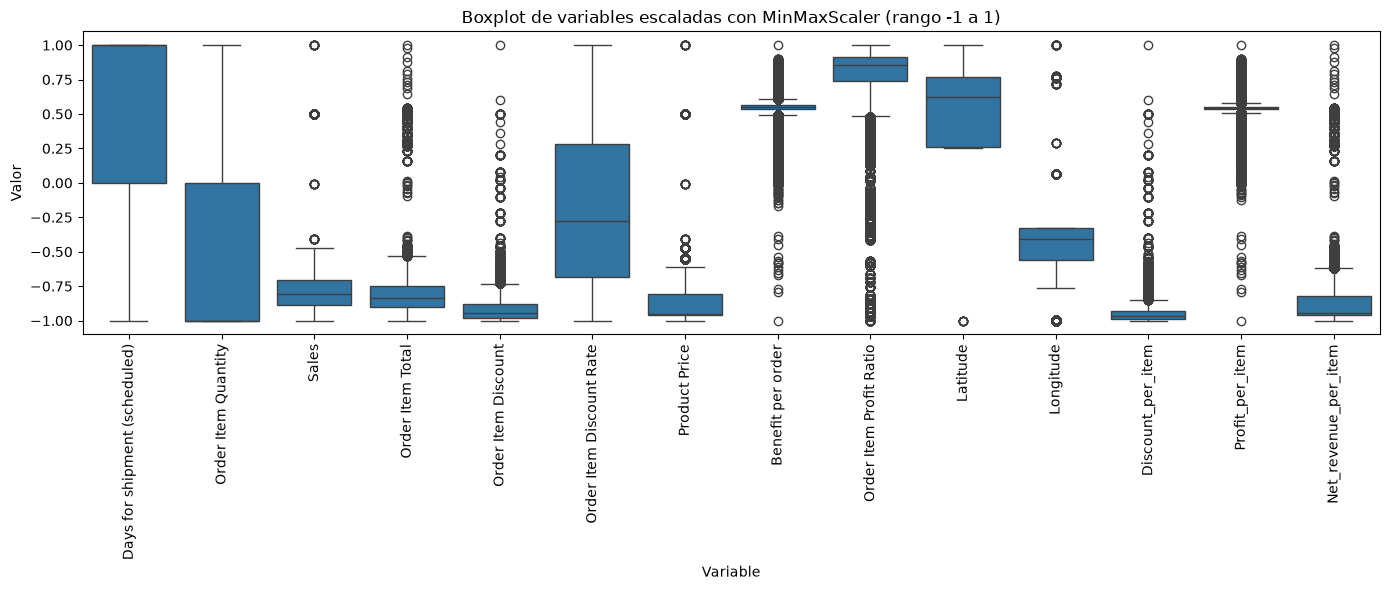

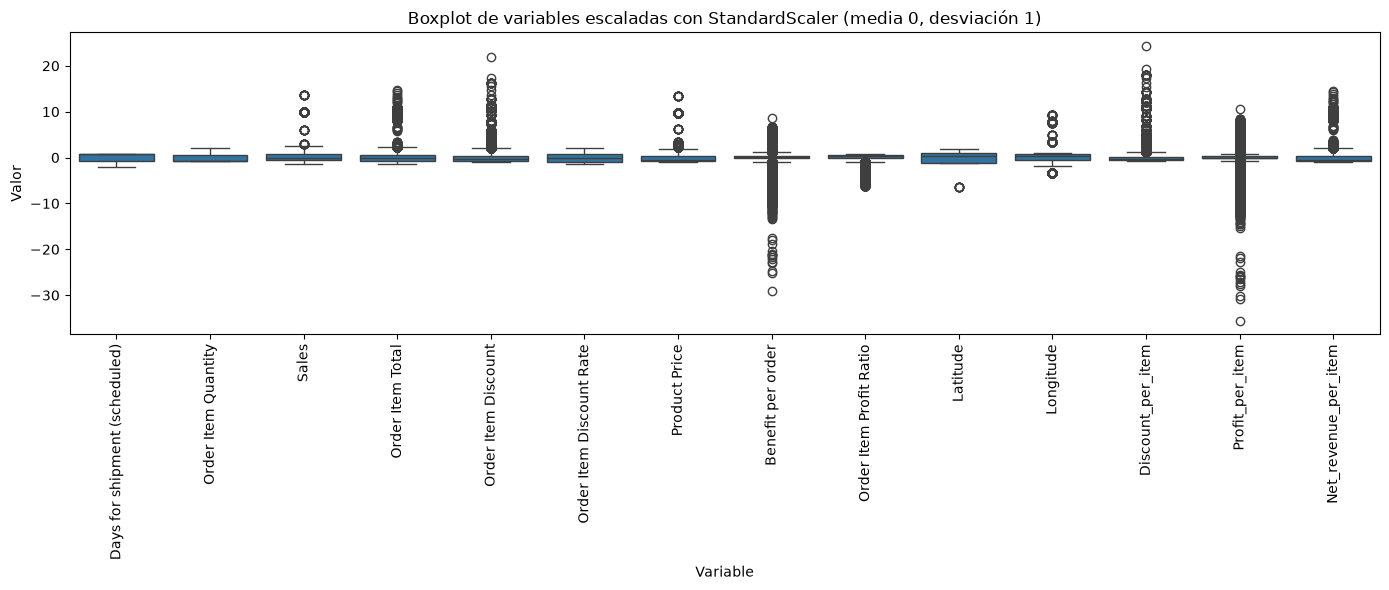

In [56]:
import seaborn as sns

for nombre, datos in [("MinMaxScaler (rango -1 a 1)", df_train_min_max),
                      ("StandardScaler (media 0, desviación 1)", df_train_std)]:
    datos_largos = datos.melt(var_name="Variable", value_name="Valor")

    plt.figure(figsize=(14, 6))
    sns.boxplot(data=datos_largos, x="Variable", y="Valor")
    plt.xticks(rotation=90)
    plt.title(f"Boxplot de variables escaladas con {nombre}")
    plt.tight_layout()
    plt.show()

In [57]:
# Porcentaje de valores atípicos por variable (criterio 1.5 x RIC)
q1 = df_train_escalado[variables_escalado].quantile(0.25)
q3 = df_train_escalado[variables_escalado].quantile(0.75)
ric = q3 - q1

es_atipico = (
    (df_train_escalado[variables_escalado] < q1 - 1.5 * ric) |
    (df_train_escalado[variables_escalado] > q3 + 1.5 * ric)
)

tabla_atipicos = pd.DataFrame({
    "Atípicos (%)": es_atipico.mean() * 100,
    "Mín. StandardScaler": df_train_std.min(),
    "Máx. StandardScaler": df_train_std.max()
}).sort_values("Atípicos (%)", ascending=False)

display(tabla_atipicos.round(2))

,Atípicos (%),Mín. StandardScaler,Máx. StandardScaler
Profit_per_item,17.45,-35.56,10.57
Benefit per order,10.54,-29.17,8.59
Discount_per_item,10.04,-0.72,24.30
Order Item Profit Ratio,9.66,-6.13,0.81
Net_revenue_per_item,4.77,-0.95,14.42
Order Item Discount,4.16,-0.95,21.96
Product Price,1.13,-0.94,13.35
Order Item Total,1.09,-1.47,14.68
Longitude,0.78,-3.41,9.34
Sales,0.26,-1.47,13.61


7.4 Interpretación.

Escalas: Con MinMaxScaler todas las variables quedaron dentro del rango de -1 a 1, pero sus cajas se ubican en posiciones muy diferentes. Las variables monetarias como Sales, Order Item Discount y Product Price quedaron concentradas cerca de -1, mientras que Benefit per order quedó concentrada alrededor de 0.55. Esto ocurre porque unos pocos valores extremos ocupan los límites del rango y comprimen al resto de los datos. Con StandardScaler, en cambio, todas las cajas quedaron centradas en 0, lo que hace que las variables sean más comparables entre sí.

Atípicos: Ambos métodos se ven afectados por los valores atípicos, pero de forma distinta. MinMaxScaler los encierra dentro del rango de -1 a 1 y, al hacerlo, comprime a la mayoría de los datos. StandardScaler no limita el rango, por lo que los atípicos se muestran claramente alejados del centro; por ejemplo, Profit_per_item alcanza -35.6 desviaciones estándar y Discount_per_item 24.3. Las variables con mayor porcentaje de atípicos son Profit_per_item (17.5 %), Benefit per order (10.5 %), Discount_per_item (10.0 %) y Order Item Profit Ratio (9.7 %), lo que coincide con lo observado en la sección 2.

En conclusión, StandardScaler deja las variables mejor alineadas y se ve menos afectado por los valores extremos que MinMaxScaler, por lo que se considera la opción más adecuada para nuestro proyecto. Las variables con muchos atípicos, especialmente las de beneficio, podrían requerir un tratamiento adicional como la transformación logarítmica, que se evalúa en la siguiente sección.

### 7.5 Transformaciones logarítmicas


In [58]:
variables_log = [
    "Sales",
    "Order Item Total",
    "Order Item Discount",
    "Product Price",
    "Discount_per_item",
    "Net_revenue_per_item"
]

# Se agregan columnas nuevas con el logaritmo; las originales se conservan
for conjunto in [df_train_escalado, df_test_escalado]:
    for col in variables_log:
        conjunto[f"log_{col}"] = np.log1p(conjunto[col])

print("Columnas nuevas creadas:")
print([f"log_{col}" for col in variables_log])

Columnas nuevas creadas:
['log_Sales', 'log_Order Item Total', 'log_Order Item Discount', 'log_Product Price', 'log_Discount_per_item', 'log_Net_revenue_per_item']


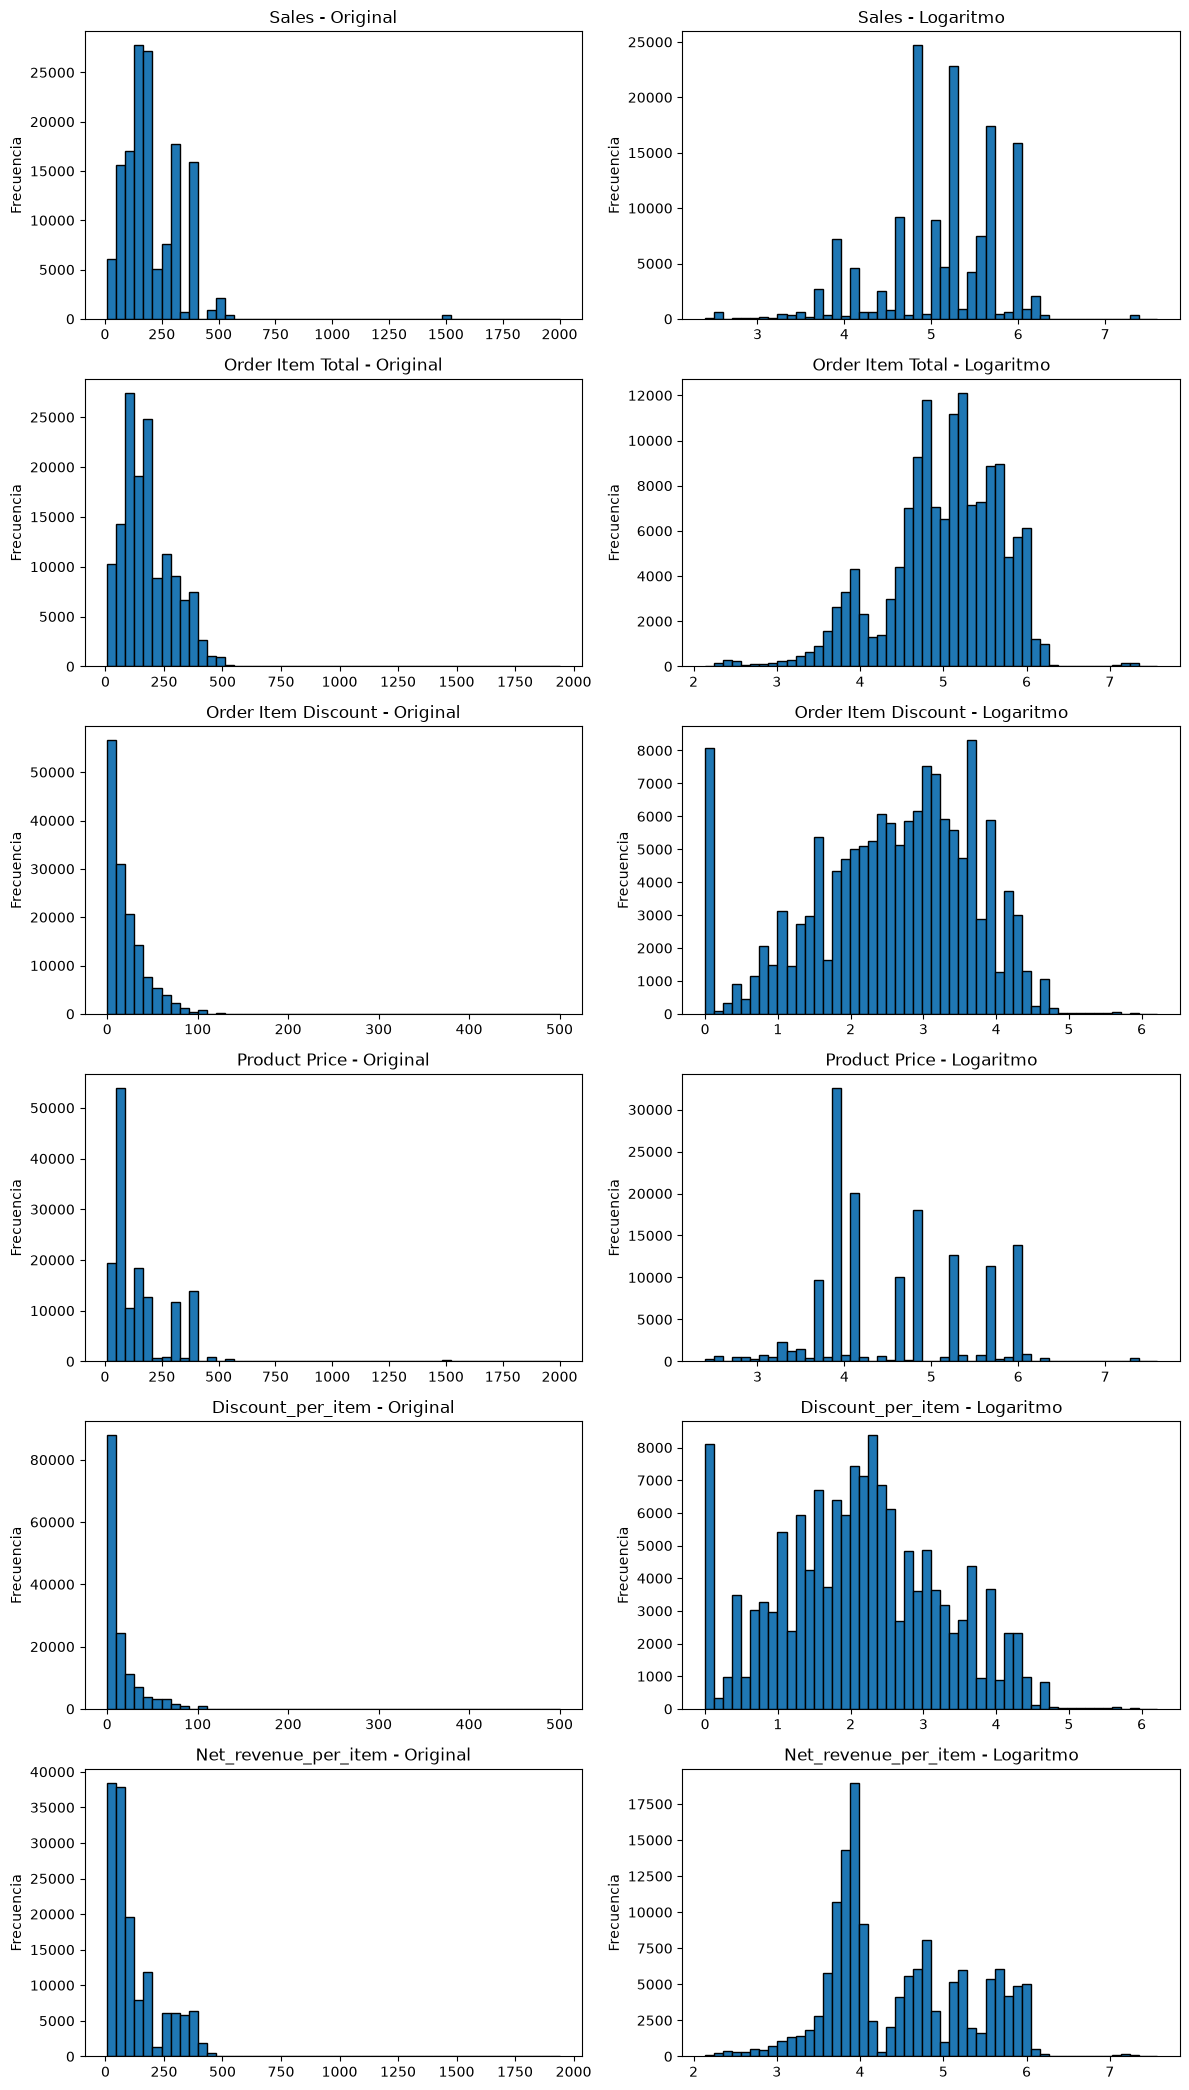

In [65]:
# Histogramas antes y después
fig, axes = plt.subplots(len(variables_log), 2, figsize=(12, 3.5 * len(variables_log)))

for i, col in enumerate(variables_log):
    axes[i, 0].hist(df_train_escalado[col], bins=50, edgecolor="black")
    axes[i, 0].set_title(f"{col} - Original")
    axes[i, 0].set_ylabel("Frecuencia")

    axes[i, 1].hist(df_train_escalado[f"log_{col}"], bins=50, edgecolor="black")
    axes[i, 1].set_title(f"{col} - Logaritmo")
    axes[i, 1].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

In [61]:
# Asimetría Antes y Después
comparacion_log = pd.DataFrame({
    "Asimetría original": df_train_escalado[variables_log].skew(),
    "Asimetría con log": [df_train_escalado[f"log_{col}"].skew() for col in variables_log]
})

display(comparacion_log.round(2))

,Asimetría original,Asimetría con log
Sales,2.85,-0.68
Order Item Total,2.83,-0.67
Order Item Discount,3.08,-0.52
Product Price,3.17,0.33
Discount_per_item,4.26,0.05
Net_revenue_per_item,3.17,0.33


7.5 Conclusiones de las transformaciones logarítmicas

Se aplicó el logaritmo a seis variables: Sales, Order Item Total, Order Item Discount, Product Price, Discount_per_item y Net_revenue_per_item. Se eligieron porque tenían muchos valores pequeños y pocos valores muy grandes, lo que hacía que sus histogramas estuvieran cargados hacia la izquierda.

Después del logaritmo, los histogramas quedaron más centrados y la asimetría bajó mucho en todas. Por ejemplo, Sales pasó de 2.85 a -0.68 y Discount_per_item de 4.26 a 0.05.

Algunas variables, como Sales y Product Price, todavía muestran varios picos. Esto pasa porque los productos tienen pocos precios distintos. En las variables de descuento queda una barra alta en 0, que son los pedidos sin descuento.

No se aplicó el logaritmo a las variables de beneficio porque tienen valores negativos. Tampoco a las coordenadas, ni a las variables con pocos valores distintos como los días programados o la cantidad.

Se conservaron las columnas originales y se agregaron las nuevas con el prefijo log_, para evaluar más adelante cuál funciona mejor en el modelo.